# Coronary Artery Stenosis **Instance Segmentation** using YOLOv8s-seg

This notebook builds an end-to-end pipeline for **coronary artery stenosis instance segmentation** in
X-ray angiography images from the **ARCADE** dataset (COCO-format annotations, single class:
`stenosis`, `category_id = 26`) using a **COCO-pretrained `yolov8s-seg` model, fine-tuned** on this data.

**What changed vs. the detection version**
- Labels are built from the COCO **polygon** field `ann["segmentation"][0]` instead of `ann["bbox"]`.
- Label format is `class x1 y1 x2 y2 ... xn yn` (normalized polygon) instead of `class xc yc w h`.
- The model is `yolov8s-seg.pt` (COCO-pretrained), fine-tuned rather than trained from scratch.
- Evaluation reports **both** Box metrics and **Mask** metrics (`metrics.seg.*`).
- Inference visualization overlays predicted **masks/contours**, and the manual cross-check uses
  **mask IoU** rather than box IoU.

**Pipeline overview**
1. Install & import dependencies
2. Configuration
3. Explore the COCO-format dataset (incl. polygon sanity checks)
4. Preprocess images to enhance vessel visibility (denoise, CLAHE, Frangi vesselness)
5. Apply preprocessing to the whole dataset
6. Convert COCO polygons -> YOLO-seg `.txt` label format
7. Build the YOLO dataset folder structure
8. `data.yaml`
9. Augmentation configuration (segmentation-aware)
10. Fine-tune the pretrained `yolov8s-seg`
11. Training curves (now includes segmentation loss)
12. Full evaluation on the held-out test set (Box + Mask metrics)
13. Numerical results table
    13b. ARCADE metrics (same protocol as the DeepLabV3+ instance network)
14. Inference: predicted masks vs. ground-truth polygons
15. Manual **mask-IoU** TP/FP/FN cross-check
16. Final combined results summary
17. Save final model
18. Extracting polygon output from predictions

> Designed to run on **Kaggle** with a GPU accelerator (P100/T4) enabled.


## 1. Install & Import Dependencies

Ultralytics YOLOv8 is a PyTorch-based implementation (no TensorFlow used anywhere in this notebook).

> **Kaggle commit version.** Run with *Save Version -> Save & Run All (Commit)*. At the end the notebook writes
> `/kaggle/working/yoloseg_deliver/` (best.pt, last.pt, results.csv, metrics, operating point, predictions) and a zip,
> so the weights survive in the notebook's **Output** tab. Download `stenosis_yolov8s_seg_best.pt` from there.
> Needs: ARCADE dataset attached via Add Input, GPU = T4 (one GPU is enough), Internet ON (downloads `yolov8s-seg.pt`).


In [1]:
# ============================================================
# 1a. Installs (Kaggle usually needs ultralytics + pycocotools)
# ============================================================
!pip install -q ultralytics
!pip install -q pycocotools
!pip install -q scikit-image
print("Installs complete.")

Installs complete.


In [2]:
# ============================================================
# 1b. Imports
# ============================================================
import os
# Reduce CUDA memory fragmentation across epochs (must be set BEFORE importing torch)
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import json
import shutil
import random
import glob
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from tqdm import tqdm

import torch
print("Torch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())

from skimage.filters import frangi
from skimage import exposure

from ultralytics import YOLO

random.seed(42)
np.random.seed(42)

Torch: 2.11.0+cu130 | CUDA available: True
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## 2. Configuration

Update `DATASET_ROOT` if your Kaggle input path differs.

Note the two segmentation-specific knobs:
- `MASK_RATIO` — Ultralytics downsamples ground-truth masks by this factor before computing the mask
  loss (default `4`). Stenosis lesions are small and thin, so a coarse mask target throws away exactly
  the detail we care about. We use `2` as a compromise between fidelity and memory; set `1` for full
  resolution if VRAM allows.
- `OVERLAP_MASK` — when `True`, all instances in an image share one index-encoded mask plane (cheaper).
  Fine here because separate stenoses rarely overlap. Set `False` if you see instances swallowing
  each other.

In [3]:
# ============================================================
# 2. Configuration
# ============================================================
# Path to the ORIGINAL dataset (as attached on Kaggle). Adjust if needed.
# Auto-find the ARCADE stenosis folder under /kaggle/input (the dataset MUST be attached with Add Input
# BEFORE "Save & Run All": a non-interactive commit cannot attach datasets by itself).
SMOKE_TEST = False     # True = 1 epoch, only to check the notebook runs end to end (~10 min). Set False for the real run.
_cands = [Path("/kaggle/input/datasets/nirmalgaud/arcade-dataset/arcade/stenosis")] + \
         [p.parent for p in Path("/kaggle/input").glob("**/stenosis/train/annotations/train.json")] + \
         [p.parent.parent.parent for p in Path("/kaggle/input").glob("**/stenosis/train/annotations/train.json")]
DATASET_ROOT = next((p for p in _cands if (p / "train" / "annotations" / "train.json").exists()), _cands[0])
if not (DATASET_ROOT / "train" / "annotations" / "train.json").exists():
    raise RuntimeError("ARCADE dataset not found. In Kaggle: Add Input -> search 'arcade-dataset' (nirmalgaud) -> Add, then Save Version -> Save & Run All.")

# Working directory where we will build the preprocessed + YOLO-formatted dataset
WORK_ROOT    = Path("/kaggle/working/stenosis_yoloseg")
PREPROC_ROOT = WORK_ROOT / "preprocessed_images"   # enhanced images (per split)
YOLO_ROOT    = WORK_ROOT / "yolo_dataset"          # final images/ + labels/ structure

SPLITS = ["train", "val", "test"]

# The single class of interest
STENOSIS_CATEGORY_ID = 26
CLASS_NAMES = ["stenosis"]   # YOLO class index 0

IMG_SIZE   = 512
BATCH_SIZE = 8
EPOCHS     = 1 if SMOKE_TEST else 200

# --- Segmentation model: COCO-pretrained yolov8s-seg, to be FINE-TUNED ---
MODEL_WEIGHTS = "yolov8s-seg.pt"
RUN_NAME      = "stenosis_yolov8s_seg"

# --- Segmentation-specific training knobs ---
MASK_RATIO   = 2      # GT mask downsample factor for the loss (Ultralytics default = 4)
OVERLAP_MASK = True   # index-encode all instances into one mask plane (memory efficient)

# --- Out-of-memory fix ---
# Validation during training runs at conf=0.001 with max_det=300. After a few epochs hundreds of
# low-confidence instances pass 0.001, and each needs a full mask + IoU -> CUDA OOM at epoch end.
# ARCADE images carry only a few stenoses, so 20 detections per image is far above any real need.
MAX_DET = 20
WORKERS = 4          # dataloader workers per GPU (lower if the OOM is host RAM, not CUDA)

# Minimum number of polygon points to accept an annotation (a polygon needs >= 3 vertices)
MIN_POLY_POINTS = 3

DEVICE = 0 if torch.cuda.is_available() else "cpu"   # single GPU (no DDP): more robust in a commit run

for p in [WORK_ROOT, PREPROC_ROOT, YOLO_ROOT]:
    p.mkdir(parents=True, exist_ok=True)

print("Dataset root:", DATASET_ROOT)
print("Work root:   ", WORK_ROOT)
print("Model:       ", MODEL_WEIGHTS, "(COCO-pretrained, will be fine-tuned)")
print("Using device:", DEVICE)
print("GPU count:   ", torch.cuda.device_count())

Dataset root: /kaggle/input/datasets/nirmalgaud/arcade-dataset/arcade/stenosis
Work root:    /kaggle/working/stenosis_yoloseg
Model:        yolov8s-seg.pt (COCO-pretrained, will be fine-tuned)
Using device: 0
GPU count:    2


## 3. Explore the COCO-format Dataset

Sanity check: load each split's JSON, confirm the schema, count images/annotations, confirm
`category_id == 26`, and — new for segmentation — verify that the `segmentation` field actually
contains usable polygons (a list of flat `[x1, y1, x2, y2, ...]` coordinate lists) rather than
RLE dictionaries.

In [4]:
# ============================================================
# 3a. Load & inspect COCO annotations for each split
# ============================================================
def load_coco(split):
    ann_path = DATASET_ROOT / split / "annotations" / f"{split}.json"
    with open(ann_path, "r") as f:
        coco = json.load(f)
    return coco

coco_data = {split: load_coco(split) for split in SPLITS}

summary_rows = []
for split, coco in coco_data.items():
    n_images        = len(coco["images"])
    n_anns          = len(coco["annotations"])
    cat_ids         = sorted(set(a["category_id"] for a in coco["annotations"]))
    n_imgs_with_ann = len(set(a["image_id"] for a in coco["annotations"]))
    summary_rows.append({
        "split": split,
        "num_images": n_images,
        "num_annotations": n_anns,
        "num_images_with_annotations": n_imgs_with_ann,
        "category_ids_present": cat_ids,
    })

summary_df = pd.DataFrame(summary_rows)
print(summary_df.to_string(index=False))

print("\nCategories (from train.json):")
for c in coco_data["train"]["categories"]:
    print(c)

split  num_images  num_annotations  num_images_with_annotations category_ids_present
train        1000             1625                          997                 [26]
  val         200              406                          200                 [26]
 test         300              386                          300                 [26]

Categories (from train.json):
{'id': 1, 'name': '1', 'supercategory': ''}
{'id': 2, 'name': '2', 'supercategory': ''}
{'id': 3, 'name': '3', 'supercategory': ''}
{'id': 4, 'name': '4', 'supercategory': ''}
{'id': 5, 'name': '5', 'supercategory': ''}
{'id': 6, 'name': '6', 'supercategory': ''}
{'id': 7, 'name': '7', 'supercategory': ''}
{'id': 8, 'name': '8', 'supercategory': ''}
{'id': 9, 'name': '9', 'supercategory': ''}
{'id': 10, 'name': '9a', 'supercategory': ''}
{'id': 11, 'name': '10', 'supercategory': ''}
{'id': 12, 'name': '10a', 'supercategory': ''}
{'id': 13, 'name': '11', 'supercategory': ''}
{'id': 14, 'name': '12', 'supercategory': ''}
{'

In [5]:
# ============================================================
# 3b. Segmentation-field audit  (NEW - specific to the seg pipeline)
# ============================================================
# We must know, before writing any labels:
#   - are segmentations polygons (list) or RLE (dict)?
#   - how many polygon parts does each annotation have?
#   - how many vertices does a typical stenosis polygon carry?
audit_rows = []
for split, coco in coco_data.items():
    n_poly, n_rle, n_multipart, n_degenerate = 0, 0, 0, 0
    vertex_counts = []
    for ann in coco["annotations"]:
        if ann["category_id"] != STENOSIS_CATEGORY_ID:
            continue
        seg = ann.get("segmentation", None)
        if isinstance(seg, dict):                 # RLE mask, not a polygon
            n_rle += 1
            continue
        if not isinstance(seg, list) or len(seg) == 0:
            n_degenerate += 1
            continue
        n_poly += 1
        if len(seg) > 1:
            n_multipart += 1
        poly = seg[0]
        if len(poly) < 2 * MIN_POLY_POINTS or len(poly) % 2 != 0:
            n_degenerate += 1
        else:
            vertex_counts.append(len(poly) // 2)

    audit_rows.append({
        "split": split,
        "polygon_anns": n_poly,
        "rle_anns": n_rle,
        "multi_part_anns": n_multipart,
        "degenerate_anns": n_degenerate,
        "min_vertices": min(vertex_counts) if vertex_counts else None,
        "median_vertices": int(np.median(vertex_counts)) if vertex_counts else None,
        "max_vertices": max(vertex_counts) if vertex_counts else None,
    })

audit_df = pd.DataFrame(audit_rows)
print(audit_df.to_string(index=False))

# Show one raw example so the format is unambiguous
example = next(a for a in coco_data["train"]["annotations"]
               if a["category_id"] == STENOSIS_CATEGORY_ID and isinstance(a.get("segmentation"), list))
print("\nExample annotation keys:", list(example.keys()))
print("bbox           :", example["bbox"])
print("segmentation[0] first 12 coords:", example["segmentation"][0][:12])
print("segmentation[0] length         :", len(example["segmentation"][0]),
      "->", len(example["segmentation"][0]) // 2, "vertices")

split  polygon_anns  rle_anns  multi_part_anns  degenerate_anns  min_vertices  median_vertices  max_vertices
train          1625         0                0                0             4               18           290
  val           406         0                0                0             5               17           353
 test           386         0                0                0             6               17            83

Example annotation keys: ['id', 'image_id', 'category_id', 'segmentation', 'area', 'bbox', 'iscrowd', 'attributes']
bbox           : [278.0, 245.12, 42.75, 54.13]
segmentation[0] first 12 coords: [278.0, 291.75, 286.75, 299.25, 289.5, 296.25, 291.75, 293.25, 294.0, 290.25, 296.5, 287.5]
segmentation[0] length         : 58 -> 29 vertices


## 4. Preprocessing: Making the Arteries Clearer

Coronary X-ray angiography images are typically low-contrast and noisy, with thin tubular vessel structures. We apply a preprocessing pipeline designed specifically for this:

1. **Grayscale normalization** — ensure single-channel intensity image.
2. **Denoising** — a mild non-local-means / Gaussian denoise to suppress acquisition noise without blurring thin vessels.
3. **CLAHE (Contrast Limited Adaptive Histogram Equalization)** — locally boosts contrast so faint vessel segments become visible without over-amplifying noise.
4. **Frangi vesselness filter** — a Hessian-based multi-scale filter that specifically highlights tubular/curvilinear structures (i.e., vessels), suppressing blob-like or planar structures. This is the classic technique used in vascular image analysis to make arteries "pop out".

Instead of throwing away the original image, we **stack all three views into a 3-channel pseudo-RGB image**:
- Channel 0: original (denoised) grayscale
- Channel 1: CLAHE-enhanced contrast
- Channel 2: Frangi vesselness map (normalized)

This gives YOLO's 3-channel input a richer signal than a single plain grayscale image, while still being visually interpretable.

In [6]:
# ============================================================
# 4a. Preprocessing functions
# ============================================================
def to_grayscale(img):
    if img.ndim == 3:
        return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return img

def denoise(gray):
    # mild denoise, preserves thin vessel edges better than large-kernel blur
    return cv2.fastNlMeansDenoising(gray, h=7, templateWindowSize=7, searchWindowSize=21)

def apply_clahe(gray, clip_limit=2.5, tile_grid_size=(8, 8)):
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    return clahe.apply(gray)

def vesselness_map(gray):
    # Frangi filter expects float image in [0, 1]; tuned scale range for vessel widths
    img_f = gray.astype(np.float32) / 255.0
    vmap = frangi(img_f, sigmas=range(1, 5), alpha=0.5, beta=0.5, black_ridges=False)
    vmap = exposure.rescale_intensity(vmap, out_range=(0, 1))
    return (vmap * 255).astype(np.uint8)

# def preprocess_image(img_bgr):
#     # Returns a 3-channel enhanced image: [denoised_gray, clahe, vesselness]
#     gray = to_grayscale(img_bgr)
#     den = denoise(gray)
#     clahe_img = apply_clahe(den)
#     vmap = vesselness_map(den)
#     enhanced = np.stack([den, clahe_img, vmap], axis=-1)  # HxWx3, uint8
#     return enhanced


def preprocess_image(img_bgr):
    # Returns a 3-channel enhanced image: [denoised_gray, clahe, vesselness]
    # gray = to_grayscale(img_bgr)
    # den = denoise(gray)
    # clahe_img = apply_clahe(den)
    # vmap = vesselness_map(den)
    # enhanced = np.stack([den, clahe_img, vmap], axis=-1)  # HxWx3, uint8
    return img_bgr

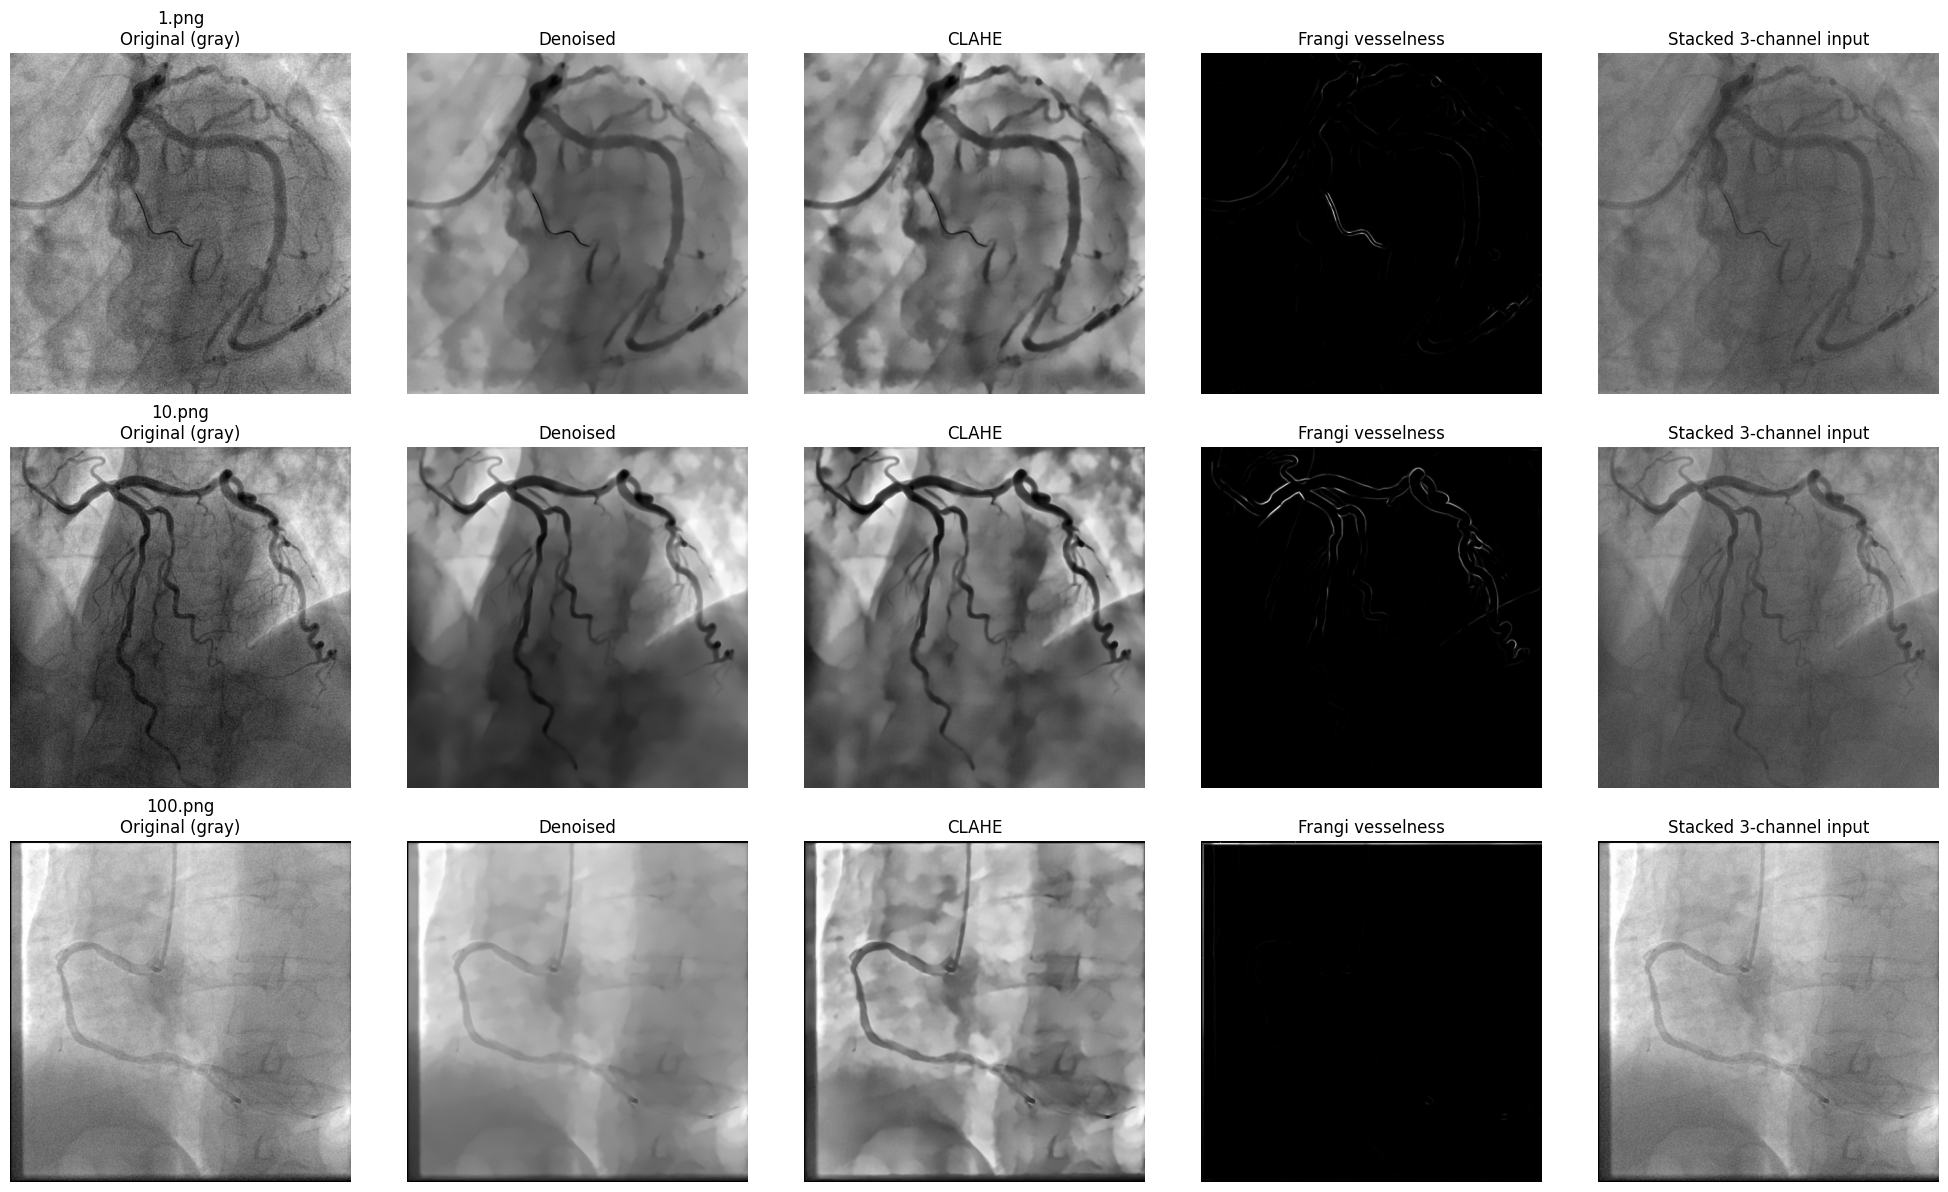

In [7]:
# ============================================================
# 4b. Visualize preprocessing on a few sample images
# ============================================================
def imread_any(path):
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    return img

sample_split = "train"
sample_img_dir = DATASET_ROOT / sample_split / "images"
sample_files = sorted(os.listdir(sample_img_dir))[:3]

fig, axes = plt.subplots(len(sample_files), 5, figsize=(20, 4 * len(sample_files)))
if len(sample_files) == 1:
    axes = axes[None, :]

for i, fname in enumerate(sample_files):
    img = imread_any(sample_img_dir / fname)
    gray = to_grayscale(img)
    den = denoise(gray)
    clahe_img = apply_clahe(den)
    vmap = vesselness_map(den)
    enhanced = preprocess_image(img)

    axes[i, 0].imshow(gray, cmap="gray"); axes[i, 0].set_title(f"{fname}\nOriginal (gray)")
    axes[i, 1].imshow(den, cmap="gray"); axes[i, 1].set_title("Denoised")
    axes[i, 2].imshow(clahe_img, cmap="gray"); axes[i, 2].set_title("CLAHE")
    axes[i, 3].imshow(vmap, cmap="gray"); axes[i, 3].set_title("Frangi vesselness")
    axes[i, 4].imshow(enhanced); axes[i, 4].set_title("Stacked 3-channel input")
    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

## 5. Apply Preprocessing to the Whole Dataset

We run the enhancement pipeline over every image in `train`, `val`, and `test` and save the results as new `.png` files. YOLO will be trained on these enhanced images rather than the raw ones.

In [8]:
# ============================================================
# 5. Apply preprocessing to all images, save to PREPROC_ROOT/<split>/
# ============================================================
def preprocess_split(split):
    src_dir = DATASET_ROOT / split / "images"
    dst_dir = PREPROC_ROOT / split
    dst_dir.mkdir(parents=True, exist_ok=True)

    files = sorted(os.listdir(src_dir))
    for fname in tqdm(files, desc=f"Preprocessing {split}"):
        src_path = src_dir / fname
        img = imread_any(src_path)
        if img is None:
            print("WARNING: could not read", src_path)
            continue
        enhanced = preprocess_image(img)
        cv2.imwrite(str(dst_dir / fname), cv2.cvtColor(enhanced, cv2.COLOR_RGB2BGR))

for split in SPLITS:
    preprocess_split(split)

print("Preprocessing complete. Enhanced images saved under:", PREPROC_ROOT)

Preprocessing test: 100%|██████████| 300/300 [00:35<00:00,  8.50it/s]

Preprocessing complete. Enhanced images saved under: /kaggle/working/stenosis_yoloseg/preprocessed_images


## 6. Convert COCO **Polygons** to YOLO-seg Format

Ultralytics' segmentation format is one row per instance:

```
class_id x1 y1 x2 y2 x3 y3 ... xn yn
```

with **all coordinates normalized to `[0, 1]`** by image width/height, and the polygon **implicitly
closed** (do not repeat the first vertex at the end).

Source of the polygon: `ann["segmentation"][0]`, a flat COCO list `[x1, y1, x2, y2, ...]` in absolute
pixels.

Handling rules applied below:
- Only `category_id == 26` annotations are kept, remapped to class index `0`.
- **Multi-part annotations**: YOLO-seg expects a single contour per instance. If `segmentation` holds
  more than one polygon part, we take the **largest by shoelace area** (which is `[0]` in the
  overwhelming majority of cases) rather than silently concatenating parts, since concatenation
  produces a self-intersecting contour that rasterizes into garbage.
- **RLE annotations** (`segmentation` is a dict) are converted to a contour via `pycocotools` +
  `cv2.findContours` so nothing is dropped silently.
- Polygons with fewer than 3 vertices, or an odd coordinate count, are skipped and counted.
- Coordinates are clipped to `[0, 1]`; annotations slightly outside the canvas would otherwise make
  Ultralytics' dataloader raise `non-normalized or out of bounds coordinates`.
- Images with no valid stenosis polygon get an **empty** label file — YOLO treats these as background
  negatives, which is correct and useful here.

In [9]:
# ============================================================
# 6a. COCO polygon -> YOLO-seg polygon conversion
# ============================================================
from pycocotools import mask as coco_mask_utils


def polygon_area(flat_poly):
    """Shoelace area of a flat [x1,y1,x2,y2,...] polygon."""
    pts = np.asarray(flat_poly, dtype=np.float64).reshape(-1, 2)
    x, y = pts[:, 0], pts[:, 1]
    return 0.5 * abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1)))


def rle_to_polygon(seg, img_h, img_w):
    """Fallback: turn an RLE segmentation into the largest external contour (flat list)."""
    if isinstance(seg["counts"], list):                 # uncompressed RLE
        rle = coco_mask_utils.frPyObjects(seg, img_h, img_w)
    else:
        rle = seg
    m = coco_mask_utils.decode(rle)
    if m.ndim == 3:
        m = m[:, :, 0]
    contours, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return None
    biggest = max(contours, key=cv2.contourArea)
    return biggest.reshape(-1).astype(np.float64).tolist()


def extract_polygon(ann, img_h, img_w):
    """Return one flat [x1,y1,...] polygon in absolute pixels, or None if unusable."""
    seg = ann.get("segmentation", None)
    if seg is None:
        return None
    if isinstance(seg, dict):                            # RLE
        return rle_to_polygon(seg, img_h, img_w)
    if not isinstance(seg, list) or len(seg) == 0:
        return None

    # Keep only well-formed parts, then take the largest. seg[0] in the normal single-part case.
    parts = [p for p in seg
             if isinstance(p, list) and len(p) >= 2 * MIN_POLY_POINTS and len(p) % 2 == 0]
    if not parts:
        return None
    return max(parts, key=polygon_area)


def polygon_to_yolo_seg(flat_poly, img_w, img_h):
    """Normalize + clip to [0,1]. Returns a flat list of normalized coords."""
    pts = np.asarray(flat_poly, dtype=np.float64).reshape(-1, 2)
    pts[:, 0] = np.clip(pts[:, 0] / img_w, 0.0, 1.0)
    pts[:, 1] = np.clip(pts[:, 1] / img_h, 0.0, 1.0)
    return pts.reshape(-1).tolist()


def convert_split_to_yolo_seg_labels(split, coco, label_out_dir):
    label_out_dir.mkdir(parents=True, exist_ok=True)

    images_by_id  = {im["id"]: im for im in coco["images"]}
    anns_by_image = defaultdict(list)
    for ann in coco["annotations"]:
        if ann["category_id"] == STENOSIS_CATEGORY_ID:
            anns_by_image[ann["image_id"]].append(ann)

    n_with_poly, n_empty, n_instances, n_skipped = 0, 0, 0, 0

    for img_id, img_info in images_by_id.items():
        stem         = Path(img_info["file_name"]).stem
        img_w, img_h = img_info["width"], img_info["height"]

        lines = []
        for ann in anns_by_image.get(img_id, []):
            poly = extract_polygon(ann, img_h, img_w)
            if poly is None:
                n_skipped += 1
                continue
            norm = polygon_to_yolo_seg(poly, img_w, img_h)
            if len(norm) < 2 * MIN_POLY_POINTS:
                n_skipped += 1
                continue
            coords = " ".join(f"{v:.6f}" for v in norm)
            lines.append(f"0 {coords}")
            n_instances += 1

        with open(label_out_dir / f"{stem}.txt", "w") as f:
            f.write("\n".join(lines))

        if lines:
            n_with_poly += 1
        else:
            n_empty += 1

    print(f"[{split}] {n_with_poly} label files with polygons "
          f"({n_instances} instances), {n_empty} empty (background), "
          f"{n_skipped} annotations skipped as unusable.")

## 7. Build the Final YOLO Dataset Folder Structure

Ultralytics expects:

```
yolo_dataset/
    images/
        train/*.png  val/*.png  test/*.png
    labels/
        train/*.txt  val/*.txt  test/*.txt
```

We copy the **preprocessed** images (from Step 5) into `images/<split>/` and write the YOLO labels (from Step 6) into `labels/<split>/`.

In [10]:
# ============================================================
# 7. Assemble YOLO-seg dataset directory
# ============================================================
for split in SPLITS:
    img_dst = YOLO_ROOT / "images" / split
    lbl_dst = YOLO_ROOT / "labels" / split
    img_dst.mkdir(parents=True, exist_ok=True)
    lbl_dst.mkdir(parents=True, exist_ok=True)

    # copy preprocessed images
    src_img_dir = PREPROC_ROOT / split
    for fname in tqdm(os.listdir(src_img_dir), desc=f"Copying images ({split})"):
        shutil.copy(src_img_dir / fname, img_dst / fname)

    # write YOLO-seg polygon labels
    convert_split_to_yolo_seg_labels(split, coco_data[split], lbl_dst)

print("YOLO-seg dataset assembled at:", YOLO_ROOT)

Copying images (train): 100%|██████████| 1000/1000 [00:00<00:00, 3774.21it/s]


[train] 997 label files with polygons (1625 instances), 3 empty (background), 0 annotations skipped as unusable.


Copying images (val): 100%|██████████| 200/200 [00:00<00:00, 3646.95it/s]


[val] 200 label files with polygons (406 instances), 0 empty (background), 0 annotations skipped as unusable.


Copying images (test): 100%|██████████| 300/300 [00:00<00:00, 3984.92it/s]


[test] 300 label files with polygons (386 instances), 0 empty (background), 0 annotations skipped as unusable.
YOLO-seg dataset assembled at: /kaggle/working/stenosis_yoloseg/yolo_dataset


In [11]:
# ============================================================
# 7b. Sanity check A: validate every label file parses as a legal YOLO-seg row
# ============================================================
def validate_seg_labels(lbl_dir):
    bad = []
    n_rows = 0
    for p in sorted(Path(lbl_dir).glob("*.txt")):
        for ln, line in enumerate(open(p), start=1):
            line = line.strip()
            if not line:
                continue
            n_rows += 1
            parts = line.split()
            coords = parts[1:]
            if len(coords) % 2 != 0:
                bad.append((p.name, ln, "odd coordinate count"))
            elif len(coords) < 2 * MIN_POLY_POINTS:
                bad.append((p.name, ln, f"only {len(coords)//2} vertices"))
            else:
                vals = np.array(coords, dtype=float)
                if vals.min() < 0.0 or vals.max() > 1.0:
                    bad.append((p.name, ln, "coords outside [0,1]"))
    return n_rows, bad


for split in SPLITS:
    n_rows, bad = validate_seg_labels(YOLO_ROOT / "labels" / split)
    print(f"[{split}] {n_rows} polygon rows | {len(bad)} problems")
    for b in bad[:5]:
        print("   ", b)

[train] 1625 polygon rows | 0 problems
[val] 406 polygon rows | 0 problems
[test] 386 polygon rows | 0 problems


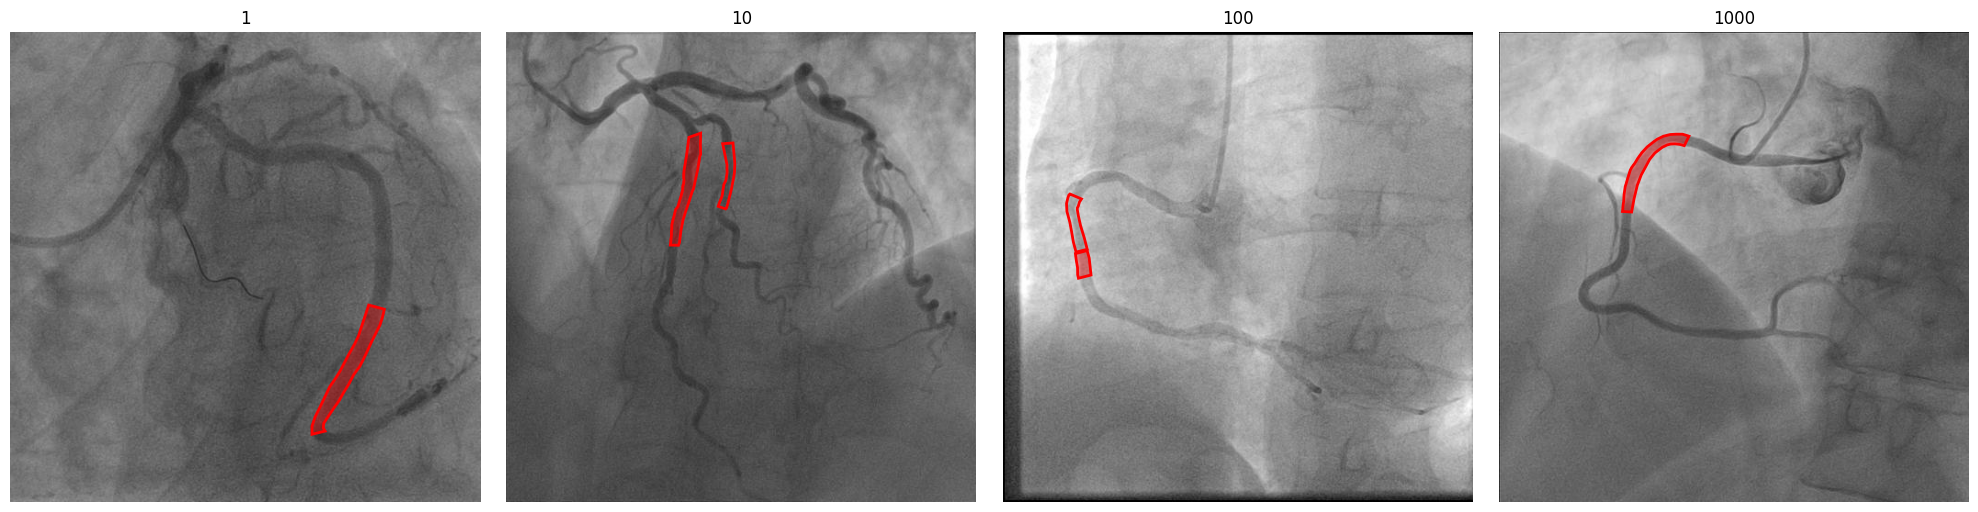

In [12]:
# ============================================================
# 7c. Sanity check B: draw YOLO-seg polygons back onto the images
# ============================================================
def draw_yolo_seg_labels(img_path, label_path, ax, title=""):
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    ax.imshow(img)

    if Path(label_path).exists():
        for line in open(label_path):
            line = line.strip()
            if not line:
                continue
            vals = line.split()
            pts = np.array(vals[1:], dtype=float).reshape(-1, 2)
            pts[:, 0] *= w
            pts[:, 1] *= h

            # filled translucent mask + crisp outline
            overlay = img.copy()
            cv2.fillPoly(overlay, [pts.astype(np.int32)], (255, 0, 0))
            ax.imshow(cv2.addWeighted(overlay, 0.35, img, 0.65, 0))
            ax.add_patch(patches.Polygon(pts, closed=True, linewidth=2,
                                         edgecolor="red", facecolor="none"))
    ax.set_title(title)
    ax.axis("off")


train_img_dir = YOLO_ROOT / "images" / "train"
train_lbl_dir = YOLO_ROOT / "labels" / "train"

files_with_polys = [f for f in sorted(os.listdir(train_lbl_dir))
                    if os.path.getsize(train_lbl_dir / f) > 0][:4]

fig, axes = plt.subplots(1, len(files_with_polys), figsize=(5 * len(files_with_polys), 5))
if len(files_with_polys) == 1:
    axes = [axes]
for ax, lbl_fname in zip(axes, files_with_polys):
    stem = Path(lbl_fname).stem
    draw_yolo_seg_labels(train_img_dir / f"{stem}.png", train_lbl_dir / lbl_fname, ax, title=stem)
plt.tight_layout()
plt.show()

## 8. `data.yaml`

This file tells Ultralytics where the images/labels live and the class names.

In [13]:
# ============================================================
# 8. Write data.yaml
# ============================================================
data_yaml_content = f'''path: {YOLO_ROOT}
train: images/train
val: images/val
test: images/test

names:
  0: stenosis
'''

data_yaml_path = WORK_ROOT / "data.yaml"
with open(data_yaml_path, "w") as f:
    f.write(data_yaml_content)

print(data_yaml_content)
print("Saved to:", data_yaml_path)

path: /kaggle/working/stenosis_yoloseg/yolo_dataset
train: images/train
val: images/val
test: images/test

names:
  0: stenosis

Saved to: /kaggle/working/stenosis_yoloseg/data.yaml


## 9. Augmentation — Segmentation-aware Settings

Ultralytics applies augmentation internally and **transforms the polygons along with the pixels**, so
no separate Albumentations pipeline is needed. The reasoning from the detection version still holds
(small medical dataset, single modality, so geometric augmentation yes / aggressive color augmentation
no), with two additions that only exist for the segmentation task:

- **`copy_paste`** — pastes instance masks from one image into another. It is genuinely useful on
  natural images, but here it would paste a stenosis lesion onto a location with no vessel underneath,
  producing an anatomically impossible sample and teaching the model a texture prior instead of a
  vascular one. We keep it at `0.0`. Raise it only if you also constrain paste locations to vessel
  pixels.
- **`mask_ratio` / `overlap_mask`** — set in the config cell and passed to `train()` below.

`mosaic` also deserves a second look for segmentation: it shrinks each image to a quadrant, so a lesion
occupying ~1% of the frame becomes sub-pixel-thin in the downsampled mask target. It is kept but
reduced, and `close_mosaic` disables it for the final epochs.


### Fix: disable Ultralytics' Ray Tune callback

Kaggle notebooks often ship a `ray` version whose internal API no longer matches what Ultralytics' built-in Ray Tune callback expects. This callback fires every epoch **even if you are not using Ray Tune**, and on mismatched versions it crashes training with:

```
AttributeError: module 'ray.train._internal.session' has no attribute '_get_session'
```

We disable this integration in Ultralytics' persistent settings (safe, one-time, has no effect on your training results/metrics — Ray Tune just isn't used here).

In [14]:
# ============================================================
# Fix: disable Ultralytics' Ray Tune integration (Kaggle ray-version mismatch)
# ============================================================
from ultralytics import settings
settings.update({"raytune": False})
print("raytune setting:", settings.get("raytune"))

raytune setting: False


In [15]:
# ============================================================
# 9. Augmentation configuration (passed directly to model.train())
# ============================================================
augmentation_params = dict(
    hsv_h=0.0,        # no hue shift (single-modality, grayscale-like images)
    hsv_s=0.2,        # mild saturation jitter (3-channel pseudo-RGB input)
    hsv_v=0.3,        # mild brightness jitter, mimics acquisition exposure variation
    degrees=10.0,     # small rotations
    translate=0.10,   # small translation
    scale=0.30,       # scale jitter
    shear=2.0,        # very small shear
    perspective=0.0,  # no perspective warp (unrealistic for angiography)
    flipud=0.0,       # no vertical flip
    fliplr=0.5,       # horizontal flip mirrors left/right coronary views
    mosaic=0.6,       # reduced vs detection: mosaic shrinks already-tiny lesion masks
    mixup=0.1,        # light mixup
    copy_paste=0.0,   # OFF - pasting lesions off-vessel is anatomically invalid (see markdown)
    close_mosaic=10,  # disable mosaic for the final 10 epochs
)

for k, v in augmentation_params.items():
    print(f"{k:13s}: {v}")

hsv_h        : 0.0
hsv_s        : 0.2
hsv_v        : 0.3
degrees      : 10.0
translate    : 0.1
scale        : 0.3
shear        : 2.0
perspective  : 0.0
flipud       : 0.0
fliplr       : 0.5
mosaic       : 0.6
mixup        : 0.1
copy_paste   : 0.0
close_mosaic : 10


## 10. Fine-tune the Pretrained YOLOv8s-seg

`YOLO("yolov8s-seg.pt")` downloads the **COCO-pretrained instance segmentation checkpoint**. Passing
`pretrained=True` to `train()` keeps those weights as the initialization: the backbone, neck, and the
mask-prototype branch all start from features learned on 80-class COCO segmentation, and only the
detection/classification head is re-shaped for our single class. That transfer is what makes a few
hundred angiograms trainable at all.

Ultralytics automatically:
- logs **box loss**, **segmentation loss**, **classification loss**, and **DFL loss** each epoch,
- tracks **P, R, mAP@0.5, mAP@0.5:0.95** for **both boxes and masks** on the val split every epoch,
- saves `best.pt` / `last.pt`,
- writes `results.csv`, confusion matrix, and separate `Box*` and `Mask*` PR/F1 curves.

**Out-of-memory fix.** Training previously crashed with CUDA OOM after a few epochs. The cause is the
per-epoch validation pass, not the training step: it runs at `conf=0.001`, `max_det=300`. In the first
epochs almost no prediction clears 0.001, but once the model warms up, hundreds per image do, and the
segment validator builds and upsamples a mask for each one to match against ground truth. With two GPUs,
GPU 0 does this while still holding its training memory. `max_det=MAX_DET` (20) removes the spike;
`expandable_segments` (set in 1b) limits fragmentation growth over epochs.

In [16]:
!pip uninstall -y ray
# !python -m pip uninstall -y ray
# !pip install ray==2.9.3

Found existing installation: ray 2.59.0
Uninstalling ray-2.59.0:
  Successfully uninstalled ray-2.59.0


In [17]:
import ultralytics

print("Ultralytics version:", ultralytics.__version__)

Ultralytics version: 8.4.212


In [18]:
# ============================================================
# 10. Fine-tune the model
# ============================================================
model = YOLO(MODEL_WEIGHTS)          # COCO-pretrained yolov8s-seg
print("Task:", model.task)           # -> 'segment'

train_results = model.train(
    data=str(data_yaml_path),
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    project=str(WORK_ROOT / "runs"),
    name=RUN_NAME,
    patience=25,              # early stopping patience
    optimizer="auto",
    lr0=0.01,
    seed=42,
    pretrained=True,          # fine-tune from the COCO weights
    verbose=True,
    plots=True,
    # --- segmentation-specific ---
    mask_ratio=MASK_RATIO,    # GT mask downsample factor for the loss
    overlap_mask=OVERLAP_MASK,
    # --- OOM fix ---
    max_det=MAX_DET,          # caps masks built during per-epoch validation
    workers=WORKERS,
    **augmentation_params,
)

Task: segment
Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/stenosis_yoloseg/data.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.2, hsv_v=0.3, imgsz=512, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=2, max_det=20, mixup=0.1, mode=train, model=yolov8s-seg.pt, momentum=0.937, mosaic=0.6, multi_scale=0.0, name=stenosis_yolov8s_seg, nbs=64,

In [19]:
# RUN_DIR = Path(train_results.save_dir)
# print("Training run saved at:", RUN_DIR)

In [20]:
try:
    RUN_DIR = Path(model.trainer.save_dir)      # exact run folder (safe even if the name got a numeric suffix)
except Exception:
    RUN_DIR = WORK_ROOT / "runs" / RUN_NAME
print("Training run saved at:", RUN_DIR)

Training run saved at: /kaggle/working/stenosis_yoloseg/runs/stenosis_yolov8s_seg


## 11. Training Curves (Losses + Metrics per Epoch)

For the segment task `results.csv` gains a `train/seg_loss` and `val/seg_loss` column, and the metric
columns split into `metrics/*(B)` (box) and `metrics/*(M)` (mask). The plotting code below picks these
up automatically and separates box from mask curves.

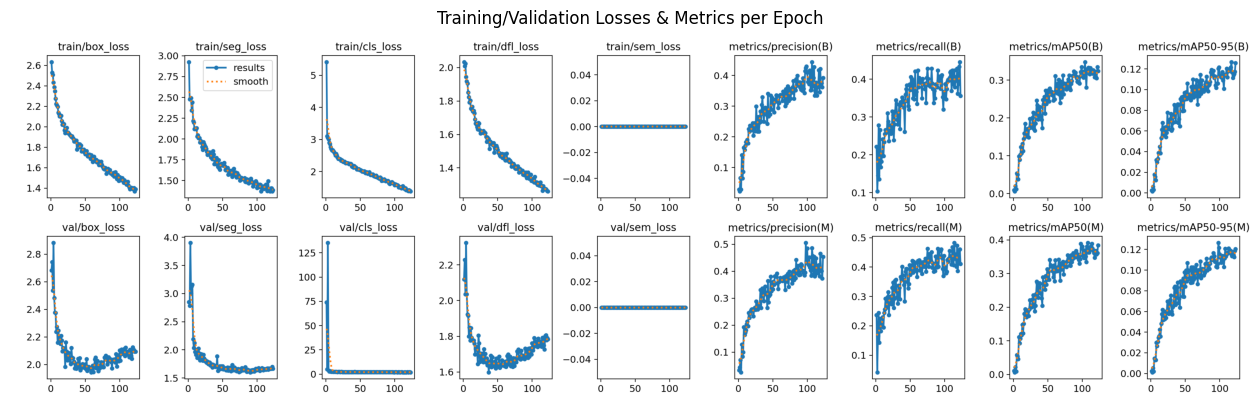

In [21]:
# ============================================================
# 11a. Show Ultralytics' auto-generated results.png
# ============================================================
results_png = RUN_DIR / "results.png"
if results_png.exists():
    img = plt.imread(results_png)
    plt.figure(figsize=(16, 10))
    plt.imshow(img)
    plt.axis("off")
    plt.title("Training/Validation Losses & Metrics per Epoch")
    plt.show()
else:
    print("results.png not found at", results_png)

     epoch     time  train/box_loss  train/seg_loss  train/cls_loss  \
118    119  2000.31         1.39241         1.37036         1.41929   
119    120  2017.28         1.38835         1.40955         1.40049   
120    121  2034.09         1.40124         1.40974         1.42527   
121    122  2050.89         1.36805         1.37205         1.40138   
122    123  2067.68         1.39001         1.38660         1.38445   

     train/dfl_loss  train/sem_loss  metrics/precision(B)  metrics/recall(B)  \
118         1.27411               0               0.42142            0.36207   
119         1.27347               0               0.36856            0.38816   
120         1.26752               0               0.37437            0.43350   
121         1.26107               0               0.36172            0.44581   
122         1.25938               0               0.39206            0.35581   

     metrics/mAP50(B)  ...  metrics/mAP50(M)  metrics/mAP50-95(M)  \
118           0.32226  

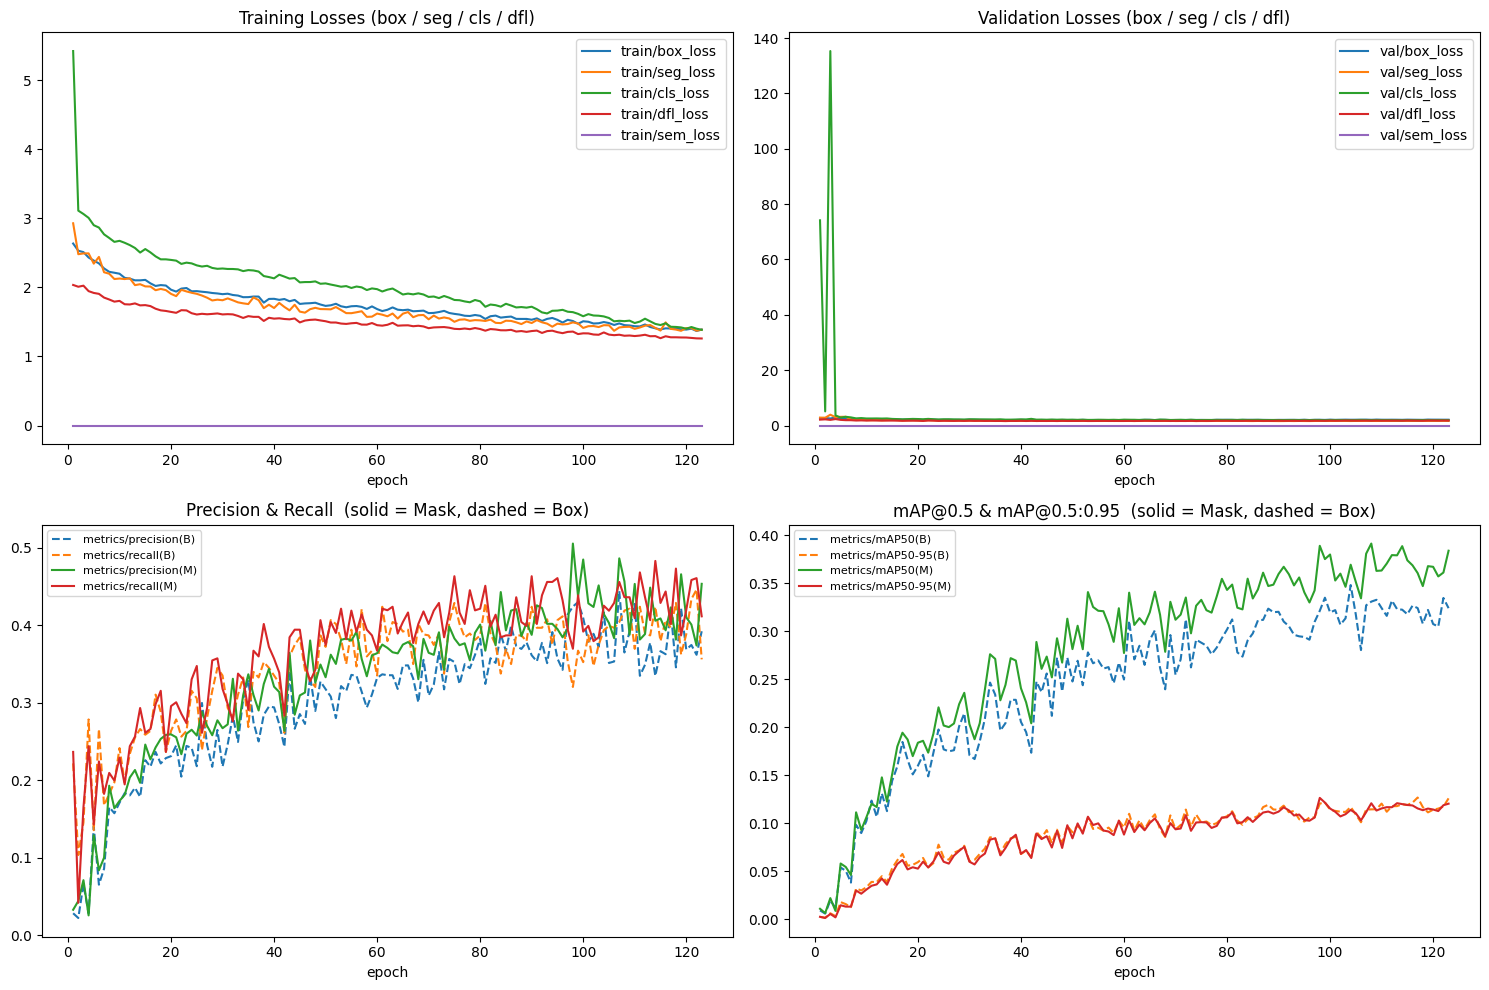

In [22]:
# ============================================================
# 11b. Plot losses and metrics from results.csv
# ============================================================
results_csv = RUN_DIR / "results.csv"
hist_df = pd.read_csv(results_csv)
hist_df.columns = [c.strip() for c in hist_df.columns]
print(hist_df.tail())

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# --- Losses (now includes seg_loss) ---
for c in [c for c in hist_df.columns if c.startswith("train/") and "loss" in c]:
    axes[0, 0].plot(hist_df["epoch"], hist_df[c], label=c)
axes[0, 0].set_title("Training Losses (box / seg / cls / dfl)")
axes[0, 0].set_xlabel("epoch"); axes[0, 0].legend()

for c in [c for c in hist_df.columns if c.startswith("val/") and "loss" in c]:
    axes[0, 1].plot(hist_df["epoch"], hist_df[c], label=c)
axes[0, 1].set_title("Validation Losses (box / seg / cls / dfl)")
axes[0, 1].set_xlabel("epoch"); axes[0, 1].legend()

# --- Precision / Recall, box (B) vs mask (M) ---
pr_cols = [c for c in hist_df.columns
           if ("precision" in c.lower() or "recall" in c.lower())]
for c in pr_cols:
    style = "-" if c.rstrip().endswith("(M)") else "--"
    axes[1, 0].plot(hist_df["epoch"], hist_df[c], style, label=c)
axes[1, 0].set_title("Precision & Recall  (solid = Mask, dashed = Box)")
axes[1, 0].set_xlabel("epoch"); axes[1, 0].legend(fontsize=8)

# --- mAP, box (B) vs mask (M) ---
map_cols = [c for c in hist_df.columns if "map" in c.lower()]
for c in map_cols:
    style = "-" if c.rstrip().endswith("(M)") else "--"
    axes[1, 1].plot(hist_df["epoch"], hist_df[c], style, label=c)
axes[1, 1].set_title("mAP@0.5 & mAP@0.5:0.95  (solid = Mask, dashed = Box)")
axes[1, 1].set_xlabel("epoch"); axes[1, 1].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 12. Full Evaluation on the Held-out Test Set

`model.val(split="test")` on a segmentation model returns **two** metric containers:

- `metrics.box.*` — detection quality of the bounding boxes derived from the same head
- `metrics.seg.*` — **mask** quality, where the IoU used for matching is computed between the predicted
  and ground-truth **masks**, not their boxes

`metrics.seg.map50` is the headline number for this task. Reporting only the box numbers would hide
the fact that a model can localize a lesion correctly while delineating its extent poorly — which is
precisely the failure mode that matters when the mask is meant to indicate lesion extent along a vessel.

In [23]:
# ============================================================
# 12a. Load best checkpoint & evaluate on the TEST split
# ============================================================
BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
best_model = YOLO(str(BEST_WEIGHTS))

test_metrics = best_model.val(
    data=str(data_yaml_path),
    split="test",
    imgsz=IMG_SIZE,
    device=DEVICE,
    max_det=MAX_DET,
    project=str(WORK_ROOT / "runs"),
    name=f"{RUN_NAME}_test_eval",
    plots=True,
)


def f1_from(p, r):
    return 2 * p * r / (p + r + 1e-16)


box_p, box_r = float(test_metrics.box.mp), float(test_metrics.box.mr)
seg_p, seg_r = float(test_metrics.seg.mp), float(test_metrics.seg.mr)
box_f1, seg_f1 = f1_from(box_p, box_r), f1_from(seg_p, seg_r)

print("=" * 55)
print("TEST SET METRICS")
print("=" * 55)
print(f"{'':16s}{'BOX':>12s}{'MASK':>12s}")
print(f"{'Precision':16s}{box_p:>12.4f}{seg_p:>12.4f}")
print(f"{'Recall':16s}{box_r:>12.4f}{seg_r:>12.4f}")
print(f"{'F1':16s}{box_f1:>12.4f}{seg_f1:>12.4f}")
print(f"{'mAP@0.5':16s}{float(test_metrics.box.map50):>12.4f}{float(test_metrics.seg.map50):>12.4f}")
print(f"{'mAP@0.5:0.95':16s}{float(test_metrics.box.map):>12.4f}{float(test_metrics.seg.map):>12.4f}")

TEST_EVAL_DIR = Path(test_metrics.save_dir)
print("\nTest evaluation artifacts saved at:", TEST_EVAL_DIR)

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLOv8s-seg summary (fused): 85 layers, 11,779,987 parameters, 0 gradients, 39.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3916.0±968.1 MB/s, size: 351.0 KB)
val: Scanning /kaggle/working/stenosis_yoloseg/yolo_dataset/labels/test... 300 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 300/300 385.1it/s 0.8s
val: New cache created: /kaggle/working/stenosis_yoloseg/yolo_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 3.6it/s 5.3s
                   all        300        386      0.325      0.331      0.224     0.0791      0.391      0.417      0.282     0.0778
Speed: 0.8ms preprocess, 10.0ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to /kaggle/working/stenosis_yoloseg/runs/stenosis_yolov8s_seg_test_eval
TEST SET METRICS
           

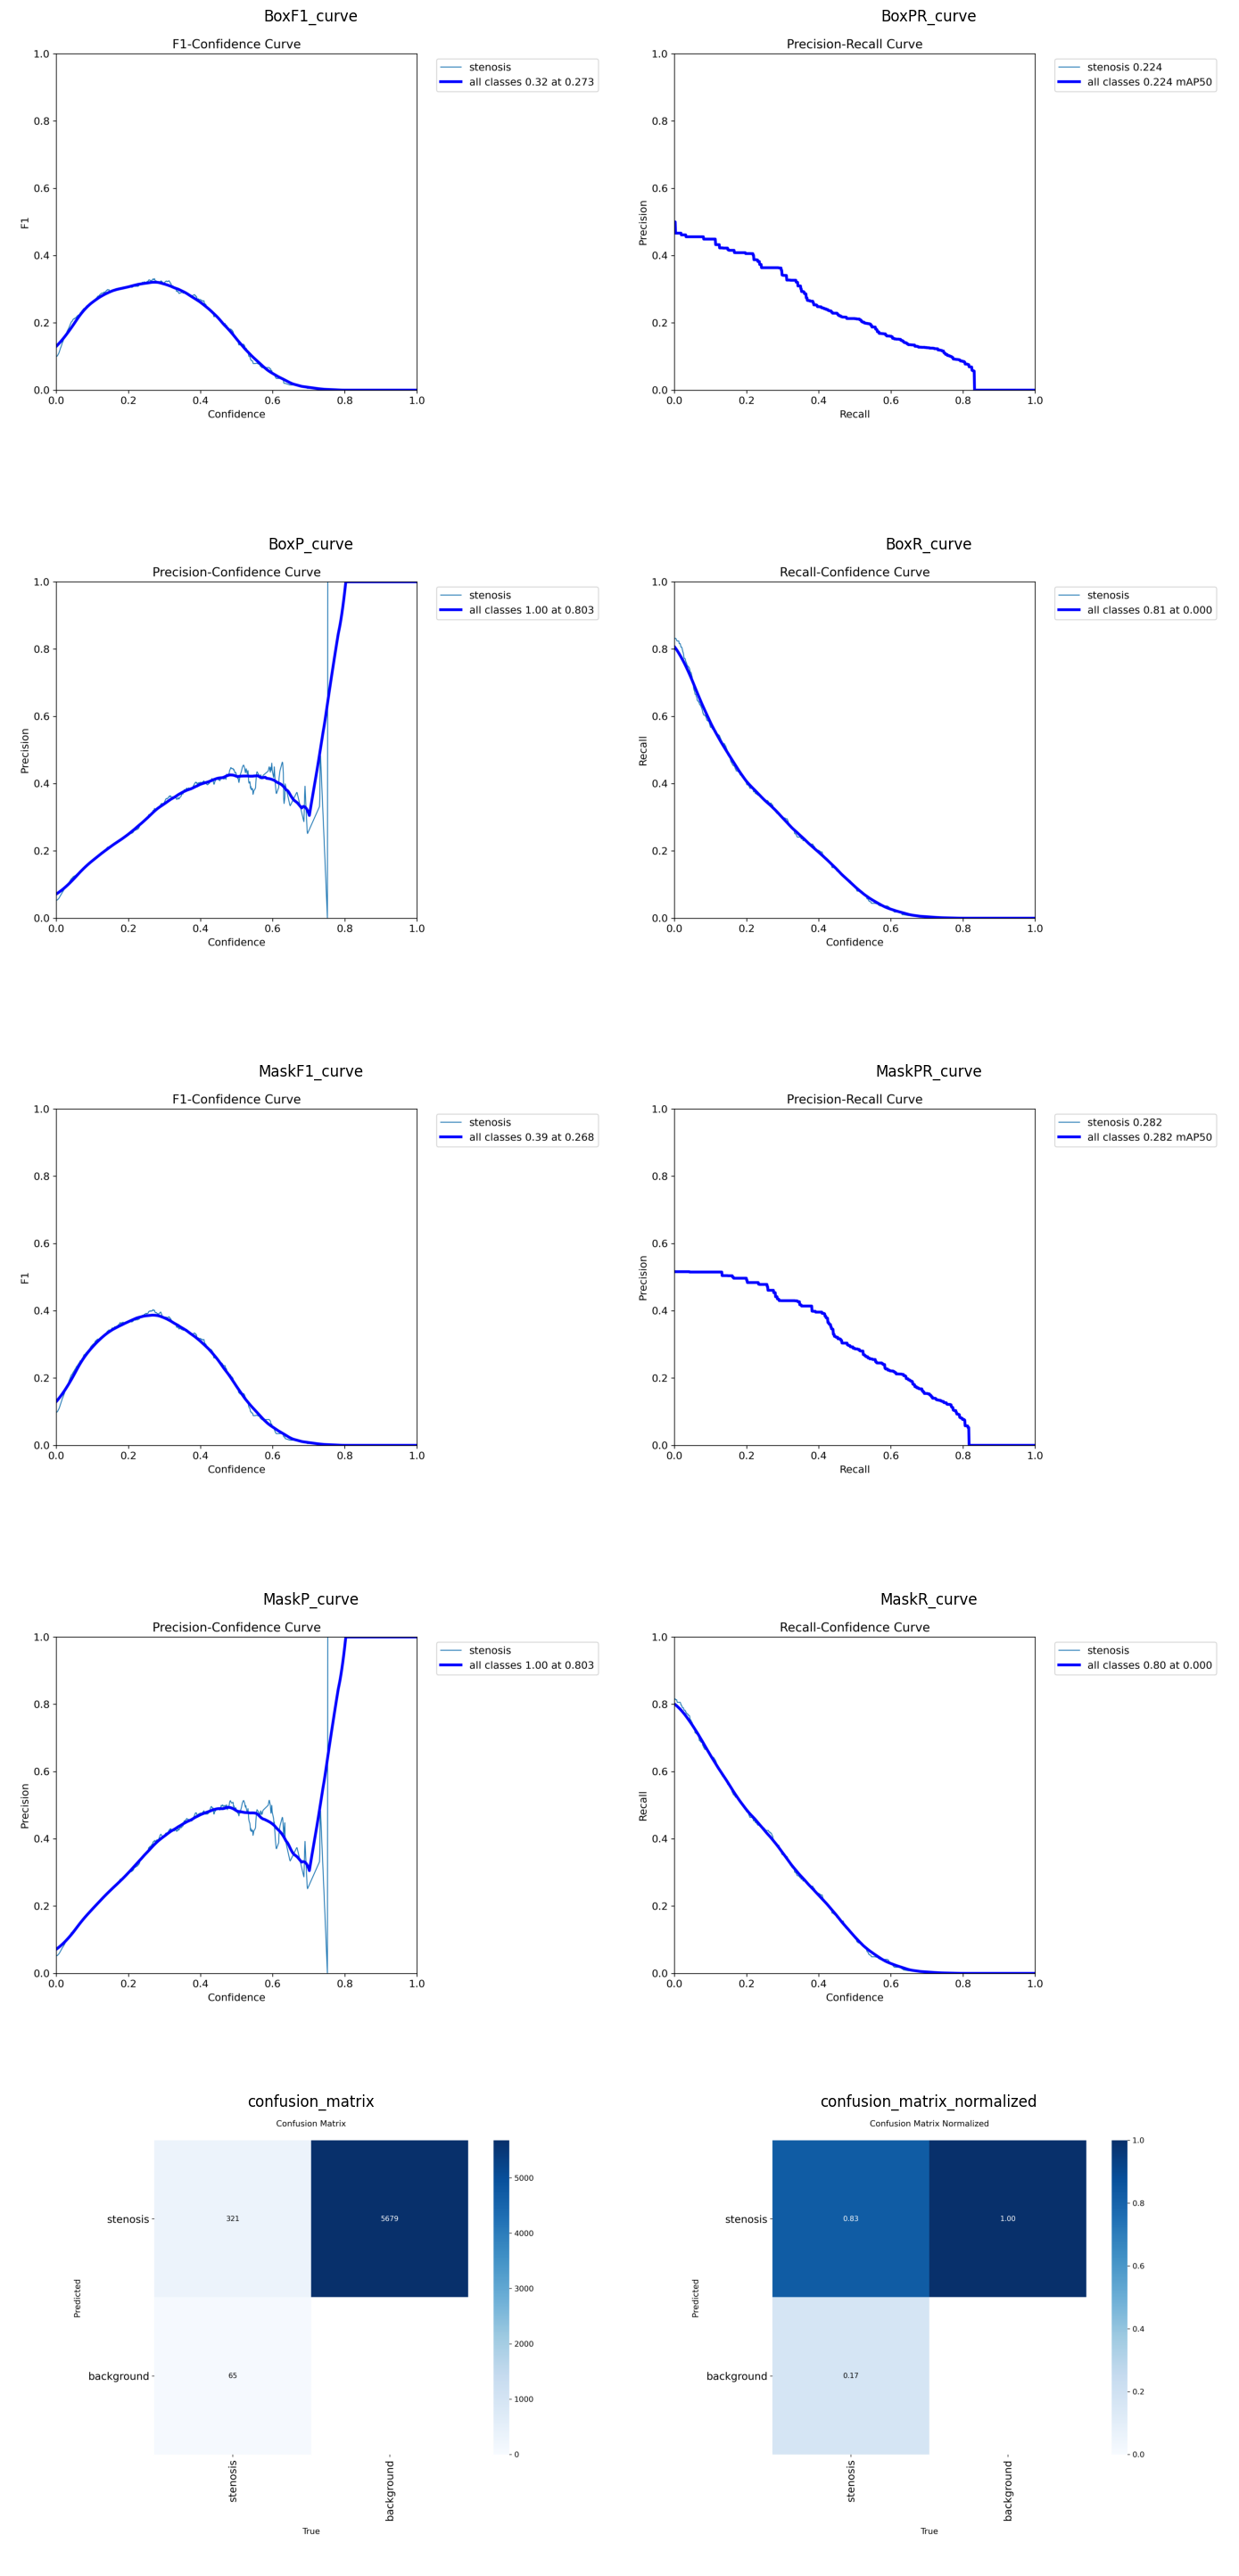

In [24]:
# ============================================================
# 12b. Display auto-generated curves (Box* and Mask* variants)
# ============================================================
png_files = sorted(TEST_EVAL_DIR.glob("*.png"))
curve_files = [p for p in png_files
               if any(k in p.name for k in ["PR_curve", "F1_curve", "P_curve",
                                            "R_curve", "confusion_matrix"])]

if not curve_files:
    print("No curve plots found in", TEST_EVAL_DIR)
else:
    n = len(curve_files)
    ncols = 2
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 6 * nrows))
    axes = np.atleast_1d(axes).flatten()
    for ax, path in zip(axes, curve_files):
        ax.imshow(plt.imread(path))
        ax.set_title(path.stem)
        ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 13. Numerical Results Table

Single-class problem, so per-class equals overall. We report the Box and Mask rows side by side.

In [25]:
# ============================================================
# 13. Build a clean results summary table
# ============================================================
results_summary = pd.DataFrame([
    {
        "Class": "stenosis",
        "Metric set": "Box",
        "Precision": round(box_p, 4),
        "Recall": round(box_r, 4),
        "F1-score": round(box_f1, 4),
        "mAP@0.5": round(float(test_metrics.box.map50), 4),
        "mAP@0.5:0.95": round(float(test_metrics.box.map), 4),
    },
    {
        "Class": "stenosis",
        "Metric set": "Mask",
        "Precision": round(seg_p, 4),
        "Recall": round(seg_r, 4),
        "F1-score": round(seg_f1, 4),
        "mAP@0.5": round(float(test_metrics.seg.map50), 4),
        "mAP@0.5:0.95": round(float(test_metrics.seg.map), 4),
    },
])

print(results_summary.to_string(index=False))

results_summary.to_csv(WORK_ROOT / "final_test_metrics.csv", index=False)
print("\nSaved to:", WORK_ROOT / "final_test_metrics.csv")

   Class Metric set  Precision  Recall  F1-score  mAP@0.5  mAP@0.5:0.95
stenosis        Box     0.3246  0.3312    0.3279   0.2241        0.0791
stenosis       Mask     0.3906  0.4171    0.4034   0.2820        0.0778

Saved to: /kaggle/working/stenosis_yoloseg/final_test_metrics.csv


## 13b. ARCADE Metrics (same protocol as the DeepLabV3+ instance network)

The Ultralytics numbers above use Ultralytics' own matching. To compare YOLOv8-seg with the
DeepLabV3+ instance network on **identical** terms, this section re-scores the predicted masks with the
exact metric code of that notebook:

| Metric | Definition |
|---|---|
| **Official ARCADE mean F1 score** | Per image, predicted and ground-truth lesions are matched greedily by Dice; a matched pair scores its Dice, every unmatched prediction or ground-truth lesion scores 0; averaged over pairs, then over images |
| **Instance-level precision / recall / F1 score (IoU ≥ 0.5)** | A predicted lesion is a true positive if its mask IoU with a ground-truth lesion is at least 0.5 |
| **Pixel-level Dice coefficient / IoU (Jaccard index), pooled** | Computed over all test pixels together |
| **Pixel-level Dice coefficient / IoU, per image** | Computed per image, then mean ± standard deviation over images |
| **Mask mean average precision at IoU 0.5 / 0.5:0.95** | COCO-style mask AP (101-point interpolation), single class, on the ranked list of predicted lesions before the final score cut-off |
| **Lesion count exact-match accuracy / within ±1 / mean absolute error** | Number of predicted lesions per image compared with the number of ground-truth lesions |

Ground truth is rasterised from the **original COCO polygons** (all parts) at native resolution, not from the
YOLO label files. Predicted masks are taken at native resolution (`retina_masks=True`), with the box
confidence as the lesion score. The selection (confidence cut-off `tau`, maximum lesions per image, always keep
the top lesion) is chosen on the re-weighted validation set — the test set is not used for any choice.

Predictions are run in chunks of 8 images: a Python list passed as `source` is otherwise loaded into memory and forwarded as a single batch, which runs out of GPU memory. `max_det=MAX_DET` caps the ranked list at 20 lesions per image (test images average 1.3), which leaves mask AP effectively unchanged.

In [26]:
# ============================================================
# 13b-1. Instances, ground truth from COCO polygons, ARCADE metrics
# ============================================================
import itertools

# ============================================================
# 2. COCO -> instances; images and instance label maps cached in RAM
# ============================================================
class Inst:
    """One instance mask, cropped to its bounding box."""
    __slots__ = ("y0", "x0", "m", "area", "score", "extra")

    def __init__(self, y0, x0, m, score=1.0, extra=None):
        self.y0, self.x0, self.m = int(y0), int(x0), m
        self.area = int(m.sum())
        self.score, self.extra = float(score), extra

    @property
    def y1(self): return self.y0 + self.m.shape[0]
    @property
    def x1(self): return self.x0 + self.m.shape[1]


def inst_from_full(full_bool, score=1.0):
    ys, xs = np.nonzero(full_bool)
    if len(ys) == 0:
        return None
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    return Inst(y0, x0, full_bool[y0:y1, x0:x1].copy(), score)


def inst_inter(a, b):
    y0, y1 = max(a.y0, b.y0), min(a.y1, b.y1)
    x0, x1 = max(a.x0, b.x0), min(a.x1, b.x1)
    if y0 >= y1 or x0 >= x1:
        return 0
    return int(np.count_nonzero(a.m[y0 - a.y0:y1 - a.y0, x0 - a.x0:x1 - a.x0] &
                                b.m[y0 - b.y0:y1 - b.y0, x0 - b.x0:x1 - b.x0]))


def inst_dice(a, b):
    s = a.area + b.area
    return 0.0 if s == 0 else 2.0 * inst_inter(a, b) / s


def inst_iou(a, b):
    i = inst_inter(a, b)
    u = a.area + b.area - i
    return 0.0 if u == 0 else i / u


def paint(insts, shape):
    canvas = np.zeros(shape, bool)
    for i in insts:
        canvas[i.y0:i.y1, i.x0:i.x1] |= i.m
    return canvas


def polys_to_mask(segs, h, w):
    full = np.zeros((h, w), np.uint8)
    for poly in segs or []:
        if isinstance(poly, list) and len(poly) >= 6:
            cv2.fillPoly(full, [np.round(np.array(poly, np.float32).reshape(-1, 2)).astype(np.int32)], 1)
    return full


def load_split(split):
    with open(DATASET_ROOT / split / "annotations" / f"{split}.json") as f:
        coco = json.load(f)
    anns = {}
    for a in coco["annotations"]:
        if a["category_id"] == STENOSIS_CATEGORY_ID:
            anns.setdefault(a["image_id"], []).append(a)
    items = []
    for im in sorted(coco["images"], key=lambda d: d["id"]):
        h, w = im["height"], im["width"]
        gts = [g for g in (inst_from_full(polys_to_mask(a.get("segmentation"), h, w).astype(bool))
                           for a in anns.get(im["id"], [])) if g is not None]
        items.append({"file": im["file_name"], "path": DATASET_ROOT / split / "images" / im["file_name"],
                      "shape": (h, w), "gts": gts})
    return items


DATA = {s: load_split(s) for s in ["val", "test"]}
for s in DATA:
    n = sum(len(it["gts"]) for it in DATA[s])
    print(f"{s:5s}: {len(DATA[s])} images | {n} lesions | {n / len(DATA[s]):.2f} per image")
DATA["train"] = load_split("train")          # only needed for the validation re-weighting below


def inst_greedy_match(preds, gts, criterion="dice"):
    fn = inst_dice if criterion == "dice" else inst_iou
    pairs = []
    for i, p in enumerate(preds):
        for j, g in enumerate(gts):
            s = fn(p, g)
            if s > 0:
                pairs.append((s, i, j))
    pairs.sort(key=lambda t: -t[0])
    up, ug, out = set(range(len(preds))), set(range(len(gts))), []
    for s, i, j in pairs:
        if i in up and j in ug:
            out.append((i, j, s)); up.discard(i); ug.discard(j)
    return out, len(up), len(ug)


def p1_image(preds, gts):
    if not preds and not gts:
        return 1.0
    pairs, n_up, n_ug = inst_greedy_match(preds, gts, "dice")
    scores = [s for _, _, s in pairs] + [0.0] * (n_up + n_ug)
    return float(np.mean(scores))


def p1_split(preds_by_img, items, weights=None):
    s = np.array([p1_image(preds_by_img[k], it["gts"]) for k, it in enumerate(items)])
    return float(s.mean()) if weights is None else float((s * weights).sum() / weights.sum())


def full_metrics(preds_by_img, items):
    p1, p1s, dimg, iimg = [], [], [], []
    TP = FP = FN = pTP = pFP = pFN = 0
    for k, it in enumerate(items):
        preds, gts = preds_by_img[k], it["gts"]
        p1.append(p1_image(preds, gts))
        pairs, n_up, n_ug = inst_greedy_match(preds, gts, "iou")
        sc, tp = [], 0
        for i, j, s in pairs:
            if s >= 0.5:
                sc.append(inst_dice(preds[i], gts[j])); tp += 1
            else:
                sc += [0.0, 0.0]
        sc += [0.0] * (n_up + n_ug)
        p1s.append(float(np.mean(sc)) if sc else 1.0)
        TP += tp; FP += len(preds) - tp; FN += len(gts) - tp
        pr, gt = paint(preds, it["shape"]), paint(gts, it["shape"])
        a, b, c = np.count_nonzero(pr & gt), np.count_nonzero(pr & ~gt), np.count_nonzero(~pr & gt)
        pTP += a; pFP += b; pFN += c
        dimg.append(1.0 if a + b + c == 0 else 2 * a / (2 * a + b + c))
        iimg.append(1.0 if a + b + c == 0 else a / (a + b + c))
    P, R = TP / max(TP + FP, 1e-9), TP / max(TP + FN, 1e-9)
    return {"P1": float(np.mean(p1)), "P1_strict": float(np.mean(p1s)),
            "F1": 2 * P * R / max(P + R, 1e-9), "Precision": P, "Recall": R, "TP": TP, "FP": FP, "FN": FN,
            "Dice": 2 * pTP / max(2 * pTP + pFP + pFN, 1e-9), "IoU": pTP / max(pTP + pFP + pFN, 1e-9),
            "pix_prec": pTP / max(pTP + pFP, 1e-9), "pix_rec": pTP / max(pTP + pFN, 1e-9),
            "Dice_img": float(np.mean(dimg)), "Dice_img_std": float(np.std(dimg)),
            "IoU_img": float(np.mean(iimg)), "IoU_img_std": float(np.std(iimg)),
            "per_image_P1": p1, "pred_per_img": (TP + FP) / len(items)}


def mask_map(ranked_by_img, items, thrs=np.arange(0.50, 0.96, 0.05)):
    """COCO-style mask AP: greedy by score over the whole split, 101-point interpolation. Returns (AP50, AP50-95)."""
    ious = [np.array([[inst_iou(p, g) for g in it["gts"]] for p in ranked_by_img[k]], np.float32)
            .reshape(len(ranked_by_img[k]), len(it["gts"])) for k, it in enumerate(items)]
    n_gt = sum(len(it["gts"]) for it in items)
    order = sorted(((p.score, k, i) for k, ps in enumerate(ranked_by_img) for i, p in enumerate(ps)),
                   key=lambda d: -d[0])
    aps = []
    for thr in thrs:
        used = [np.zeros(len(it["gts"]), bool) for it in items]
        tp = np.zeros(len(order))
        for n, (_, k, i) in enumerate(order):
            if ious[k].shape[1] == 0:
                continue
            cand = np.where(~used[k], ious[k][i], -1.0)
            j = int(cand.argmax())
            if cand[j] >= thr:
                used[k][j] = True; tp[n] = 1
        ctp, cfp = np.cumsum(tp), np.cumsum(1 - tp)
        rec = ctp / max(n_gt, 1)
        prec = np.maximum.accumulate((ctp / np.maximum(ctp + cfp, 1e-9))[::-1])[::-1] if len(order) else np.zeros(0)
        aps.append(float(np.mean([prec[rec >= r].max() if np.any(rec >= r) else 0.0
                                  for r in np.linspace(0, 1, 101)])))
    return aps[0], float(np.mean(aps))


# val re-weighting: each val image weighted by p_train(n) / p_val(n), n = #GT lesions (capped at 4)
def _count_dist(items):
    c = np.array([min(len(it["gts"]), 4) for it in items if it["gts"]])
    return {k: float(np.mean(c == k)) for k in range(1, 5)}


P_TRAIN, P_VAL = _count_dist(DATA["train"]), _count_dist(DATA["val"])
VAL_W = np.array([P_TRAIN[min(max(len(it["gts"]), 1), 4)] / max(P_VAL[min(max(len(it["gts"]), 1), 4)], 1e-9)
                  for it in DATA["val"]])
VAL_W = VAL_W / VAL_W.mean()
print("lesions/image (1,2,3,4+): train", [round(P_TRAIN[k], 3) for k in range(1, 5)],
      "| val", [round(P_VAL[k], 3) for k in range(1, 5)])
_g = DATA["val"][0]["gts"]
print("Official ARCADE mean F1 self-check (perfect prediction):", p1_image(_g, _g), "| with one extra false positive:",
      round(p1_image(_g + [Inst(0, 0, np.ones((3, 3), bool))], _g), 3))

val  : 200 images | 406 lesions | 2.03 per image
test : 300 images | 386 lesions | 1.29 per image
lesions/image (1,2,3,4+): train [0.585, 0.28, 0.084, 0.051] | val [0.41, 0.31, 0.18, 0.1]
Official ARCADE mean F1 self-check (perfect prediction): 1.0 | with one extra false positive: 0.5


In [27]:
# ============================================================
# 13b-2. YOLOv8-seg predictions -> instances; selection chosen on validation
# ============================================================
PRED_DEVICE = 0 if torch.cuda.is_available() else "cpu"   # predict() runs on a single device
PRED_CONF   = 0.001                                       # keep (almost) everything; selection below decides


def yolo_candidates(model, split, chunk=8):
    """Per image (same order as DATA[split]): list of Inst, score = box confidence, mask at native size.

    OOM fix: a Python list passed as `source` is loaded in memory and run as ONE batch
    (all 200/300 images at once -> 12+ GiB of activations). Predict in small chunks instead.
    """
    out = []
    items = DATA[split]
    for s in range(0, len(items), chunk):
        batch = items[s:s + chunk]
        paths = [str(YOLO_ROOT / "images" / split / it["file"]) for it in batch]
        results = model.predict(source=paths, imgsz=IMG_SIZE, conf=PRED_CONF, retina_masks=True,
                                max_det=MAX_DET, device=PRED_DEVICE, verbose=False)
        for it, r in zip(batch, results):
            insts = []
            if r.masks is not None:
                ms = r.masks.data.cpu().numpy() > 0.5
                cf = r.boxes.conf.cpu().numpy()
                h, w = it["shape"]
                for m, c in zip(ms, cf):
                    if m.shape != (h, w):
                        m = cv2.resize(m.astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST).astype(bool)
                    ins = inst_from_full(m, float(c))
                    if ins is not None:
                        insts.append(ins)
            out.append(sorted(insts, key=lambda i: -i.score))
        del results
        torch.cuda.empty_cache()
    return out


def select(cands, tau, max_k=99, top1=False):
    cs = sorted(cands, key=lambda c: -c.score)
    kept = [c for c in cs if c.score >= tau]
    if not kept and top1 and cs:
        kept = [cs[0]]
    return kept[:max_k]


CANDS = {s: yolo_candidates(best_model, s) for s in ["val", "test"]}


def predict(split, p):
    return [select(c, p["tau"], p["max_k"], p["top1"]) for c in CANDS[split]]


G_SELECT = dict(tau=[0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8],
                max_k=[1, 2, 3, 99], top1=[False, True])
FINAL_P, VAL_SCORE = None, -1.0
for vals in itertools.product(*G_SELECT.values()):
    p = dict(zip(G_SELECT, vals))
    s = p1_split(predict("val", p), DATA["val"], VAL_W)
    if s > VAL_SCORE + 1e-12:
        FINAL_P, VAL_SCORE = p, s
print(f"selection chosen on validation: {FINAL_P} | validation ARCADE mean F1 (re-weighted) {VAL_SCORE:.4f}")

selection chosen on validation: {'tau': 0.3, 'max_k': 2, 'top1': True} | validation ARCADE mean F1 (re-weighted) 0.4100


In [28]:
# ============================================================
# 13b-3. Test results table (same metrics as the DeepLabV3+ instance network)
# ============================================================
TEST_PRED = predict("test", FINAL_P)
fm = full_metrics(TEST_PRED, DATA["test"])
MAP50, MAP5095 = mask_map(CANDS["test"], DATA["test"])        # ranked list before cut-off / limits
n_gt = np.array([len(it["gts"]) for it in DATA["test"]])
n_pr = np.array([len(p) for p in TEST_PRED])

rows = [
    ("Official ARCADE mean F1 score", f"{fm['P1']:.4f}"),
    ("Instance-level F1 score (IoU ≥ 0.5)", f"{fm['F1']:.4f}"),
    ("Instance-level precision (IoU ≥ 0.5)", f"{fm['Precision']:.4f}"),
    ("Instance-level recall (IoU ≥ 0.5)", f"{fm['Recall']:.4f}"),
    ("True positives / false positives / false negatives", f"{fm['TP']} / {fm['FP']} / {fm['FN']}"),
    ("Pixel-level Dice coefficient (pooled)", f"{fm['Dice']:.4f}"),
    ("Pixel-level IoU, Jaccard index (pooled)", f"{fm['IoU']:.4f}"),
    ("Pixel-level Dice coefficient per image (mean ± std)", f"{fm['Dice_img']:.4f} ± {fm['Dice_img_std']:.4f}"),
    ("Pixel-level IoU per image (mean ± std)", f"{fm['IoU_img']:.4f} ± {fm['IoU_img_std']:.4f}"),
    ("Mask mean average precision at IoU 0.5 (mAP@0.5)", f"{MAP50:.4f}"),
    ("Mask mean average precision at IoU 0.5:0.95 (mAP@0.5:0.95)", f"{MAP5095:.4f}"),
    ("Lesion count exact-match accuracy", f"{np.mean(n_pr == n_gt):.4f}"),
    ("Lesion count accuracy within ±1", f"{np.mean(np.abs(n_pr - n_gt) <= 1):.4f}"),
    ("Lesion count mean absolute error", f"{np.mean(np.abs(n_pr - n_gt)):.4f}"),
    ("Predicted / ground-truth lesions per image", f"{n_pr.mean():.2f} / {n_gt.mean():.2f}"),
]
arcade_results = pd.DataFrame(rows, columns=["Metric", "Value"])
w = max(len(m) for m, _ in rows)
print(f"TEST SET — {len(DATA['test'])} images, {int(n_gt.sum())} lesions | model: {MODEL_WEIGHTS} (fine-tuned), "
      f"imgsz {IMG_SIZE}\n")
print(f"{'Metric'.ljust(w)}   Value\n{'-' * w}   {'-' * 17}")
for m_, v_ in rows:
    print(f"{m_.ljust(w)}   {v_}")
arcade_results.to_csv(WORK_ROOT / "test_results_arcade_metrics.csv", index=False)
with open(WORK_ROOT / "final_params.json", "w") as f:
    json.dump({"model": MODEL_WEIGHTS, "imgsz": IMG_SIZE, "selection": FINAL_P, "val_P1w": VAL_SCORE}, f, indent=2)
print("\nSaved to:", WORK_ROOT / "test_results_arcade_metrics.csv")

TEST SET — 300 images, 386 lesions | model: yolov8s-seg.pt (fine-tuned), imgsz 512

Metric                                                       Value
----------------------------------------------------------   -----------------
Official ARCADE mean F1 score                                0.4542
Instance-level F1 score (IoU ≥ 0.5)                          0.4053
Instance-level precision (IoU ≥ 0.5)                         0.4118
Instance-level recall (IoU ≥ 0.5)                            0.3990
True positives / false positives / false negatives           154 / 220 / 232
Pixel-level Dice coefficient (pooled)                        0.5338
Pixel-level IoU, Jaccard index (pooled)                      0.3640
Pixel-level Dice coefficient per image (mean ± std)          0.5293 ± 0.2753
Pixel-level IoU per image (mean ± std)                       0.4045 ± 0.2421
Mask mean average precision at IoU 0.5 (mAP@0.5)             0.2941
Mask mean average precision at IoU 0.5:0.95 (mAP@0.5:0.95)   0.

## 14. Inference on Test Images — Predicted Masks vs. Ground-Truth Polygons

Ground truth is drawn as a **red polygon** (that is how it is stored). Predictions are drawn as a
**green translucent mask plus its contour**, with the confidence score. Note the asymmetry we are
visualizing: the GT is a vector polygon, the prediction is a raster mask whose contour we extract for
display.

In [29]:
# ============================================================
# 14a. Helper: plot GT polygons vs predicted masks for one image
# ============================================================
def plot_gt_vs_pred_seg(image_path, label_path, model, conf_thres=0.25,
                        ax_gt=None, ax_pred=None):
    img = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    # ---------------- Ground truth (polygons) ----------------
    gt_overlay = img.copy()
    gt_polys = []
    if Path(label_path).exists() and os.path.getsize(label_path) > 0:
        for line in open(label_path):
            line = line.strip()
            if not line:
                continue
            pts = np.array(line.split()[1:], dtype=float).reshape(-1, 2)
            pts[:, 0] *= w
            pts[:, 1] *= h
            gt_polys.append(pts)
            cv2.fillPoly(gt_overlay, [pts.astype(np.int32)], (255, 0, 0))

    ax_gt.imshow(cv2.addWeighted(gt_overlay, 0.35, img, 0.65, 0))
    for pts in gt_polys:
        ax_gt.add_patch(patches.Polygon(pts, closed=True, linewidth=2,
                                        edgecolor="red", facecolor="none"))
    ax_gt.set_title(f"Ground Truth ({len(gt_polys)} lesion(s))")
    ax_gt.axis("off")

    # ---------------- Prediction (masks) ----------------
    result = model.predict(source=str(image_path), imgsz=IMG_SIZE,
                           conf=conf_thres, verbose=False)[0]

    pred_overlay = img.copy()
    n_pred = 0
    if result.masks is not None:
        # result.masks.xy -> contours already rescaled to ORIGINAL image coordinates
        for poly, box in zip(result.masks.xy, result.boxes):
            if poly.shape[0] < 3:
                continue
            n_pred += 1
            cv2.fillPoly(pred_overlay, [poly.astype(np.int32)], (0, 255, 0))

    ax_pred.imshow(cv2.addWeighted(pred_overlay, 0.35, img, 0.65, 0))
    if result.masks is not None:
        for poly, box in zip(result.masks.xy, result.boxes):
            if poly.shape[0] < 3:
                continue
            ax_pred.add_patch(patches.Polygon(poly, closed=True, linewidth=2,
                                              edgecolor="lime", facecolor="none"))
            x1, y1 = poly[:, 0].min(), poly[:, 1].min()
            ax_pred.text(x1, max(y1 - 5, 0), f"{float(box.conf[0]):.2f}",
                         color="lime", fontsize=10, weight="bold")
    ax_pred.set_title(f"Prediction ({n_pred} mask(s), conf>={conf_thres})")
    ax_pred.axis("off")



In [30]:
# ============================================================
# 14b. Run on several random test images
# ============================================================
test_img_dir = YOLO_ROOT / "images" / "test"
test_lbl_dir = YOLO_ROOT / "labels" / "test"

all_test_files = sorted(os.listdir(test_img_dir))
sample_test_files = random.sample(all_test_files, min(20, len(all_test_files)))

fig, axes = plt.subplots(len(sample_test_files), 2, figsize=(11, 5.5 * len(sample_test_files)))
if len(sample_test_files) == 1:
    axes = axes[None, :]

for i, fname in enumerate(sample_test_files):
    stem = Path(fname).stem
    plot_gt_vs_pred_seg(test_img_dir / fname, test_lbl_dir / f"{stem}.txt",
                        best_model, conf_thres=0.25,
                        ax_gt=axes[i, 0], ax_pred=axes[i, 1])

plt.tight_layout()
plt.show()

## 15. Batch Inference + **Mask-IoU** Numerical Analysis

The detection notebook cross-checked Ultralytics with box IoU. For segmentation the meaningful
cross-check is **mask IoU**: rasterize the GT polygon and the predicted contour onto a common
full-resolution canvas, then compute pixel intersection-over-union. We report both mask-IoU and
box-IoU matching so the gap between "found the lesion" and "delineated the lesion" is explicit.

Greedy matching, highest-IoU-first, one prediction per GT — the same protocol as before.

In [31]:
# ============================================================
# 15. Manual mask-IoU (and box-IoU) TP/FP/FN tally
# ============================================================
def poly_to_mask(poly_pts, h, w):
    """Rasterize an (N,2) polygon in absolute pixel coords to a uint8 mask."""
    m = np.zeros((h, w), dtype=np.uint8)
    if poly_pts is not None and len(poly_pts) >= 3:
        cv2.fillPoly(m, [np.asarray(poly_pts, dtype=np.int32)], 1)
    return m


def mask_iou(m1, m2):
    inter = np.logical_and(m1, m2).sum()
    union = np.logical_or(m1, m2).sum()
    return inter / union if union > 0 else 0.0


def poly_to_xyxy(poly_pts):
    p = np.asarray(poly_pts, dtype=np.float64)
    return [p[:, 0].min(), p[:, 1].min(), p[:, 0].max(), p[:, 1].max()]


def iou_xyxy(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    iw, ih = max(0.0, ix2 - ix1), max(0.0, iy2 - iy1)
    inter = iw * ih
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0


def load_gt_polys(lbl_path, w, h):
    polys = []
    if Path(lbl_path).exists() and os.path.getsize(lbl_path) > 0:
        for line in open(lbl_path):
            line = line.strip()
            if not line:
                continue
            pts = np.array(line.split()[1:], dtype=float).reshape(-1, 2)
            pts[:, 0] *= w
            pts[:, 1] *= h
            polys.append(pts)
    return polys


def greedy_match(pred_items, gt_items, iou_fn, iou_thres):
    """Greedy highest-IoU-first matching. Returns (TP, FP, FN, matched_ious)."""
    pairs = []
    for pi, p in enumerate(pred_items):
        for gi, g in enumerate(gt_items):
            v = iou_fn(p, g)
            if v >= iou_thres:
                pairs.append((v, pi, gi))
    pairs.sort(reverse=True)

    used_p, used_g, ious = set(), set(), []
    for v, pi, gi in pairs:
        if pi in used_p or gi in used_g:
            continue
        used_p.add(pi); used_g.add(gi); ious.append(v)

    TP = len(ious)
    FP = len(pred_items) - TP
    FN = len(gt_items) - TP
    return TP, FP, FN, ious


def evaluate_seg_matching(model, img_dir, lbl_dir, conf_thres=0.25, iou_thres=0.5):
    mTP = mFP = mFN = 0
    bTP = bFP = bFN = 0
    all_mask_ious = []

    for fname in tqdm(sorted(os.listdir(img_dir)), desc="Manual mask-IoU eval"):
        stem = Path(fname).stem
        img_path = img_dir / fname
        img = cv2.imread(str(img_path))
        h, w = img.shape[:2]

        gt_polys = load_gt_polys(lbl_dir / f"{stem}.txt", w, h)

        result = model.predict(source=str(img_path), imgsz=IMG_SIZE,
                               conf=conf_thres, verbose=False)[0]
        pred_polys = []
        if result.masks is not None:
            pred_polys = [p for p in result.masks.xy if len(p) >= 3]

        # ---- mask IoU ----
        gt_masks   = [poly_to_mask(p, h, w) for p in gt_polys]
        pred_masks = [poly_to_mask(p, h, w) for p in pred_polys]
        tp, fp, fn, ious = greedy_match(pred_masks, gt_masks, mask_iou, iou_thres)
        mTP += tp; mFP += fp; mFN += fn
        all_mask_ious.extend(ious)

        # ---- box IoU (boxes derived from the same contours) ----
        gt_boxes   = [poly_to_xyxy(p) for p in gt_polys]
        pred_boxes = [poly_to_xyxy(p) for p in pred_polys]
        tp, fp, fn, _ = greedy_match(pred_boxes, gt_boxes, iou_xyxy, iou_thres)
        bTP += tp; bFP += fp; bFN += fn

    def prf(TP, FP, FN):
        p = TP / (TP + FP + 1e-16)
        r = TP / (TP + FN + 1e-16)
        return p, r, 2 * p * r / (p + r + 1e-16)

    mp, mr, mf = prf(mTP, mFP, mFN)
    bp, br, bf = prf(bTP, bFP, bFN)

    return {
        "mask": {"TP": mTP, "FP": mFP, "FN": mFN,
                 "Precision": mp, "Recall": mr, "F1": mf,
                 "MeanIoU_of_TPs": float(np.mean(all_mask_ious)) if all_mask_ious else 0.0},
        "box":  {"TP": bTP, "FP": bFP, "FN": bFN,
                 "Precision": bp, "Recall": br, "F1": bf},
    }


manual_metrics = evaluate_seg_matching(best_model, test_img_dir, test_lbl_dir,
                                       conf_thres=0.25, iou_thres=0.5)

print("Manual matching results (conf>=0.25, IoU>=0.5):")
for key in ["mask", "box"]:
    print(f"\n  [{key.upper()} IoU]")
    for k, v in manual_metrics[key].items():
        print(f"    {k}: {v:.4f}" if isinstance(v, float) else f"    {k}: {v}")

Manual mask-IoU eval: 100%|██████████| 300/300 [00:09<00:00, 32.46it/s]

Manual matching results (conf>=0.25, IoU>=0.5):

  [MASK IoU]
    TP: 160
    FP: 252
    FN: 226
    Precision: 0.3883
    Recall: 0.4145
    F1: 0.4010
    MeanIoU_of_TPs: 0.6718

  [BOX IoU]
    TP: 131
    FP: 281
    FN: 255
    Precision: 0.3180
    Recall: 0.3394
    F1: 0.3283


## 16. Final Combined Results Summary

In [32]:
# ============================================================
# 16. Final combined numerical results (Ultralytics vs manual cross-check)
# ============================================================
final_summary = pd.DataFrame([
    {
        "Method": "Ultralytics val() - Box (test)",
        "Precision": round(box_p, 4),
        "Recall": round(box_r, 4),
        "F1-score": round(box_f1, 4),
        "mAP@0.5": round(float(test_metrics.box.map50), 4),
        "mAP@0.5:0.95": round(float(test_metrics.box.map), 4),
    },
    {
        "Method": "Ultralytics val() - Mask (test)",
        "Precision": round(seg_p, 4),
        "Recall": round(seg_r, 4),
        "F1-score": round(seg_f1, 4),
        "mAP@0.5": round(float(test_metrics.seg.map50), 4),
        "mAP@0.5:0.95": round(float(test_metrics.seg.map), 4),
    },
    {
        "Method": "Manual mask-IoU (conf>=0.25, IoU>=0.5)",
        "Precision": round(manual_metrics["mask"]["Precision"], 4),
        "Recall": round(manual_metrics["mask"]["Recall"], 4),
        "F1-score": round(manual_metrics["mask"]["F1"], 4),
        "mAP@0.5": "-",
        "mAP@0.5:0.95": "-",
    },
    {
        "Method": "Manual box-IoU (conf>=0.25, IoU>=0.5)",
        "Precision": round(manual_metrics["box"]["Precision"], 4),
        "Recall": round(manual_metrics["box"]["Recall"], 4),
        "F1-score": round(manual_metrics["box"]["F1"], 4),
        "mAP@0.5": "-",
        "mAP@0.5:0.95": "-",
    },
])

print(final_summary.to_string(index=False))
print("\nMean mask IoU over true positives:",
      round(manual_metrics["mask"]["MeanIoU_of_TPs"], 4))

final_summary.to_csv(WORK_ROOT / "final_combined_metrics.csv", index=False)
print("\nSaved to:", WORK_ROOT / "final_combined_metrics.csv")

                                Method  Precision  Recall  F1-score mAP@0.5 mAP@0.5:0.95
        Ultralytics val() - Box (test)     0.3246  0.3312    0.3279  0.2241       0.0791
       Ultralytics val() - Mask (test)     0.3906  0.4171    0.4034   0.282       0.0778
Manual mask-IoU (conf>=0.25, IoU>=0.5)     0.3883  0.4145    0.4010       -            -
 Manual box-IoU (conf>=0.25, IoU>=0.5)     0.3180  0.3394    0.3283       -            -

Mean mask IoU over true positives: 0.6718

Saved to: /kaggle/working/stenosis_yoloseg/final_combined_metrics.csv


## 17. Save Final Model

The best checkpoint is already stored at `RUN_DIR / "weights" / "best.pt"`. We copy it to a convenient location for downloading from Kaggle's Output tab.

In [33]:
# ============================================================
# 17. Export final weights to /kaggle/working for easy download
# ============================================================
final_model_path = Path("/kaggle/working/stenosis_yolov8s_seg_best.pt")
shutil.copy(BEST_WEIGHTS, final_model_path)
print("Final trained model saved to:", final_model_path)

Final trained model saved to: /kaggle/working/stenosis_yolov8s_seg_best.pt


## 18. Extracting Polygon Output From Predictions

A trained `-seg` model gives you three things per instance, and it is worth being precise about which
is native and which is derived:

| Output | Access | Nature |
|---|---|---|
| Box | `r.boxes.xyxy` | predicted directly by the detection head |
| **Mask (raster)** | `r.masks.data` | **native** — prototype coefficients x 32 prototypes, cropped to the box |
| Polygon | `r.masks.xy` | **derived** — `cv2.findContours` run on the upsampled raster mask |

So the round trip is: polygon label -> rasterized for training -> raster mask predicted -> vectorized
back to polygon. For thin, branching structures the vectorization step can fragment or self-intersect,
so **evaluate on `masks.data`, not on `masks.xy`**, and only convert to polygons when you need vector
output downstream (e.g. writing predictions back into COCO format).

The cell below exports test-set predictions as COCO-style polygons.

In [34]:
# ============================================================
# 18. Export test-set predictions as COCO-style polygon annotations
# ============================================================
def export_predictions_to_coco(model, img_dir, out_json, conf_thres=0.25):
    images, annotations = [], []
    ann_id = 1

    for img_id, fname in enumerate(tqdm(sorted(os.listdir(img_dir)), desc="Exporting"), start=1):
        img_path = img_dir / fname
        img = cv2.imread(str(img_path))
        h, w = img.shape[:2]
        images.append({"id": img_id, "file_name": fname, "width": w, "height": h})

        r = model.predict(source=str(img_path), imgsz=IMG_SIZE,
                          conf=conf_thres, verbose=False)[0]
        if r.masks is None:
            continue

        for poly, box in zip(r.masks.xy, r.boxes):
            if len(poly) < 3:
                continue
            flat = poly.reshape(-1).astype(float).tolist()   # [x1,y1,x2,y2,...]
            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy().tolist()
            annotations.append({
                "id": ann_id,
                "image_id": img_id,
                "category_id": STENOSIS_CATEGORY_ID,
                "segmentation": [flat],
                "bbox": [x1, y1, x2 - x1, y2 - y1],
                "area": float(cv2.contourArea(poly.astype(np.float32))),
                "iscrowd": 0,
                "score": float(box.conf[0]),
            })
            ann_id += 1

    coco_out = {
        "images": images,
        "annotations": annotations,
        "categories": [{"id": STENOSIS_CATEGORY_ID, "name": "stenosis"}],
    }
    with open(out_json, "w") as f:
        json.dump(coco_out, f)
    print(f"Wrote {len(annotations)} predicted polygons over {len(images)} images -> {out_json}")


pred_json = WORK_ROOT / "test_predictions_coco.json"
export_predictions_to_coco(best_model, test_img_dir, pred_json, conf_thres=0.25)

Exporting: 100%|██████████| 300/300 [00:08<00:00, 34.53it/s]


Wrote 412 predicted polygons over 300 images -> /kaggle/working/stenosis_yoloseg/test_predictions_coco.json


## Notes & Next Steps

- If your dataset path differs, update `DATASET_ROOT` in Section 2 — nothing else needs to change.
- **Source resolution.** ARCADE frames are 512x512. `IMG_SIZE = 640` upsamples them, which costs
  compute but gives the mask head more pixels to work with on small lesions. If you want a
  no-interpolation baseline, set `IMG_SIZE = 512` and compare; treat it as an ablation rather than
  assuming either is better.
- **`MASK_RATIO` is the segmentation knob most worth sweeping** (`4` -> `2` -> `1`). Stenosis masks are
  small relative to the frame, and at `mask_ratio=4` a lesion a few pixels wide can nearly vanish from
  the loss target. Watch `val/seg_loss` and mask mAP together across the sweep.
- **Expect Mask mAP below Box mAP.** That gap is informative, not a bug — it is the cost of requiring
  correct lesion extent rather than only correct lesion location. Report both.
- If recall on small/faint stenoses is low, options in rough order of expected payoff: lower
  `MASK_RATIO`, raise `IMG_SIZE`, tune the Frangi `sigmas` range in Section 4 to match lesion scale,
  then try `yolov8m-seg`. Go up in model size last — on a dataset this size the larger variants tend to
  buy overfitting.
- The detection version of this pipeline and this one share preprocessing and splits, so their test
  numbers are directly comparable. If you report both, state clearly that the detection mAP is a Box
  metric and the segmentation headline is a Mask metric — they are not interchangeable.
- Consider k-fold cross-validation; a single split is noisy at this dataset size.

## 19. Deliverables for later use (weights survive the commit)

Copies the files the thesis needs into `/kaggle/working/yoloseg_deliver/`, writes a small JSON with the
operating point chosen on validation, and removes the big temporary image folders so the Output tab stays small.
Download `stenosis_yolov8s_seg_best.pt` (needed for the unified re-score of all models).

In [35]:
# ============================================================
# 19. Collect deliverables, then clean the big temporary folders
# ============================================================
import hashlib, zipfile, platform
DELIVER = Path("/kaggle/working/yoloseg_deliver")
DELIVER.mkdir(parents=True, exist_ok=True)

def _copy(src, name=None):
    src = Path(src)
    if src.exists():
        shutil.copy(src, DELIVER / (name or src.name))
        print("copied:", src.name)
    else:
        print("MISSING (skipped):", src)

_copy(RUN_DIR / "weights" / "best.pt", "stenosis_yolov8s_seg_best.pt")
_copy(RUN_DIR / "weights" / "last.pt", "stenosis_yolov8s_seg_last.pt")
_copy(RUN_DIR / "results.csv")
_copy(RUN_DIR / "args.yaml")
_copy(RUN_DIR / "results.png")
_copy(WORK_ROOT / "test_results_arcade_metrics.csv")
_copy(WORK_ROOT / "test_predictions_coco.json")

info = dict(
    model=MODEL_WEIGHTS, img_size=IMG_SIZE, epochs_requested=EPOCHS, batch=BATCH_SIZE, seed=42,
    smoke_test=bool(SMOKE_TEST), operating_point_chosen_on_val=FINAL_P, val_arcade_f1_reweighted=float(VAL_SCORE),
    ultralytics=__import__("ultralytics").__version__, torch=torch.__version__, python=platform.python_version(),
    gpu=(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"),
    best_sha256=hashlib.sha256((DELIVER / "stenosis_yolov8s_seg_best.pt").read_bytes()).hexdigest()
                if (DELIVER / "stenosis_yolov8s_seg_best.pt").exists() else None,
)
(DELIVER / "run_info.json").write_text(json.dumps(info, indent=2, default=str))
print(json.dumps(info, indent=2, default=str))

# zip everything (weights are already compressed; ZIP_STORED is fast)
zpath = Path("/kaggle/working/yoloseg_deliver.zip")
with zipfile.ZipFile(zpath, "w", zipfile.ZIP_STORED) as z:
    for p in sorted(DELIVER.iterdir()):
        z.write(p, p.name)
print("zip:", zpath, round(zpath.stat().st_size / 1e6, 1), "MB")

# the old Section-17 copy (kept for compatibility)
shutil.copy(BEST_WEIGHTS, Path("/kaggle/working/stenosis_yolov8s_seg_best.pt"))

# big temporary folders are rebuilt from the dataset each run -> delete to keep Output small
for d in [PREPROC_ROOT, YOLO_ROOT]:
    shutil.rmtree(d, ignore_errors=True)
print("cleaned temporary folders. DONE.")

copied: best.pt
copied: last.pt
copied: results.csv
copied: args.yaml
copied: results.png
copied: test_results_arcade_metrics.csv
copied: test_predictions_coco.json
{
  "model": "yolov8s-seg.pt",
  "img_size": 512,
  "epochs_requested": 200,
  "batch": 8,
  "seed": 42,
  "smoke_test": false,
  "operating_point_chosen_on_val": {
    "tau": 0.3,
    "max_k": 2,
    "top1": true
  },
  "val_arcade_f1_reweighted": 0.4100376482545727,
  "ultralytics": "8.4.212",
  "torch": "2.11.0+cu130",
  "python": "3.13.16",
  "gpu": "Tesla T4",
  "best_sha256": "9bcefc6e2d0668153a1879b2af2acd9e7f1b30e764577b755179bbc6a46e6d18"
}
zip: /kaggle/working/yoloseg_deliver.zip 48.8 MB
cleaned temporary folders. DONE.
